# Trabajo Práctico: Predicción de lluvia en Australia
**Aprendizaje Automático 1 - Tecnicatura en Inteligencia Artificial (FCEIA)**

El objetivo es predecir, a las 23:59 de cada día, si al día siguiente va a llover (`RainTomorrow`). Es un problema de clasificación binaria.

In [65]:
# librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.experimental import enable_iterative_imputer  # hace falta para poder importar IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)

import shap
from pathlib import Path
import joblib

SEED = 42  # semilla para que los resultados sean reproducibles

## 1. Análisis descriptivo

In [5]:
# se carga el dataset y se pasa la fecha a datetime
df = pd.read_csv("weatherAUS_2026C2.csv")
df["Date"] = pd.to_datetime(df["Date"])
print(df.shape)
df.head()

(145412, 25)


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


El archivo trae dos columnas que no son variables climáticas de entrada:
- `Unnamed: 0` no tiene información.
- `RainfallTomorrow` son los milímetros que llueven **mañana**. `RainTomorrow` es justamente "mañana llovió más de 1 mm", así que esta columna contiene la respuesta (data leakage). Si se usara como entrada, el modelo daría métricas casi perfectas pero inútiles, porque a las 23:59 de hoy ese dato no existe. Se elimina.

In [6]:
# se saca el índice sobrante y la columna que filtra el target
df = df.drop(columns=["Unnamed: 0", "RainfallTomorrow"])
print(df.shape)

(145412, 23)


In [7]:
# tipos de dato y cantidad de no nulos por columna
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145412 non-null  datetime64[ns]
 1   Location       145412 non-null  object        
 2   MinTemp        143928 non-null  float64       
 3   MaxTemp        144159 non-null  float64       
 4   Rainfall       142152 non-null  float64       
 5   Evaporation    82658 non-null   float64       
 6   Sunshine       75616 non-null   float64       
 7   WindGustDir    135096 non-null  object        
 8   WindGustSpeed  135159 non-null  float64       
 9   WindDir9am     134850 non-null  object        
 10  WindDir3pm     141186 non-null  object        
 11  WindSpeed9am   143645 non-null  float64       
 12  WindSpeed3pm   142351 non-null  float64       
 13  Humidity9am    142759 non-null  float64       
 14  Humidity3pm    140907 non-null  float64       
 15  

In [8]:
# resumen estadístico de las variables numéricas
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,145412,2013-04-04 08:55:50.149918720,2007-11-01 00:00:00,2011-01-10 00:00:00,2013-06-02 00:00:00,2015-06-14 00:00:00,2017-06-24 00:00:00,NaN
MinTemp,143928.0,12.196528,-9.7,7.6,12.0,16.9,34.1,6.417956
MaxTemp,144159.0,23.223064,-5.1,17.9,22.6,28.2,49.1,7.135927
Rainfall,142152.0,2.361516,0.0,0.0,0.0,0.8,371.0,8.479338
Evaporation,82658.0,5.468616,0.0,2.6,4.8,7.4,145.0,4.193871
Sunshine,75616.0,7.611241,0.0,4.8,8.4,10.6,14.5,3.785612
WindGustSpeed,135159.0,40.036668,6.0,31.0,38.0,48.0,135.0,13.648259
WindSpeed9am,143645.0,14.067277,0.0,7.0,13.0,19.0,130.0,8.936768
WindSpeed3pm,142351.0,18.661899,0.0,12.0,18.0,24.0,86.0,8.865457
Humidity9am,142759.0,68.861521,0.0,57.0,69.9,83.1,100.0,19.062866


In [9]:
# resumen de las variables categóricas y rango de fechas
print(df.select_dtypes("object").describe().T)
print("\nPeríodo:", df["Date"].min().date(), "a", df["Date"].max().date())
print("Cantidad de ciudades:", df["Location"].nunique())

               count unique       top    freq
Location      145412     49  Canberra    3435
WindGustDir   135096     16         W    9910
WindDir9am    134850     16         N   11754
WindDir3pm    141186     16        SE   10837
RainToday     142152      2        No  110276
RainTomorrow  142153      2        No  110281

Período: 2007-11-01 a 2017-06-24
Cantidad de ciudades: 49


### ¿Qué es cada variable?

| Variable | Tipo | Descripción |
|---|---|---|
| Date | fecha | día de la observación |
| Location | categórica | ciudad/estación donde se midió |
| MinTemp, MaxTemp | numérica (°C) | temperatura mínima y máxima del día |
| Rainfall | numérica (mm) | lluvia caída en las 24 hs previas a las 9am |
| Evaporation | numérica (mm) | evaporación (tanque clase A) en las 24 hs previas a las 9am |
| Sunshine | numérica (hs) | horas de sol brillante durante el día |
| WindGustDir | categórica | dirección de la ráfaga de viento más fuerte del día |
| WindGustSpeed | numérica (km/h) | velocidad de esa ráfaga |
| WindDir9am, WindDir3pm | categórica | dirección del viento a las 9am y 3pm |
| WindSpeed9am, WindSpeed3pm | numérica (km/h) | velocidad media del viento (10 min previos) a las 9am y 3pm |
| Humidity9am, Humidity3pm | numérica (%) | humedad relativa a las 9am y 3pm |
| Pressure9am, Pressure3pm | numérica (hPa) | presión atmosférica a nivel del mar a las 9am y 3pm |
| Cloud9am, Cloud3pm | numérica (octas, 0 a 8) | fracción del cielo cubierta por nubes |
| Temp9am, Temp3pm | numérica (°C) | temperatura a las 9am y 3pm |
| RainToday | categórica (Yes/No) | si hoy llovió más de 1 mm |
| RainTomorrow | categórica (Yes/No) | **variable objetivo**: si mañana llueve más de 1 mm |

Como la predicción se hace a las 23:59, todas las mediciones del día ya están disponibles y se pueden usar como variables de entrada.

### Datos faltantes

In [10]:
# cantidad de datos faltantes de la variable objetivo
print("Faltantes en RainTomorrow:", df["RainTomorrow"].isna().sum())

Faltantes en RainTomorrow: 3259


Las filas sin `RainTomorrow` no sirven para entrenar ni para evaluar (no tenemos la respuesta correcta), y imputar el target inventaría datos. Las eliminamos.

In [11]:
# se eliminan las filas sin target y se pasa a 0/1
df = df.dropna(subset=["RainTomorrow"]).reset_index(drop=True)
df["RainTomorrow"] = df["RainTomorrow"].map({"No": 0, "Yes": 1})
print(df.shape)

(142153, 23)


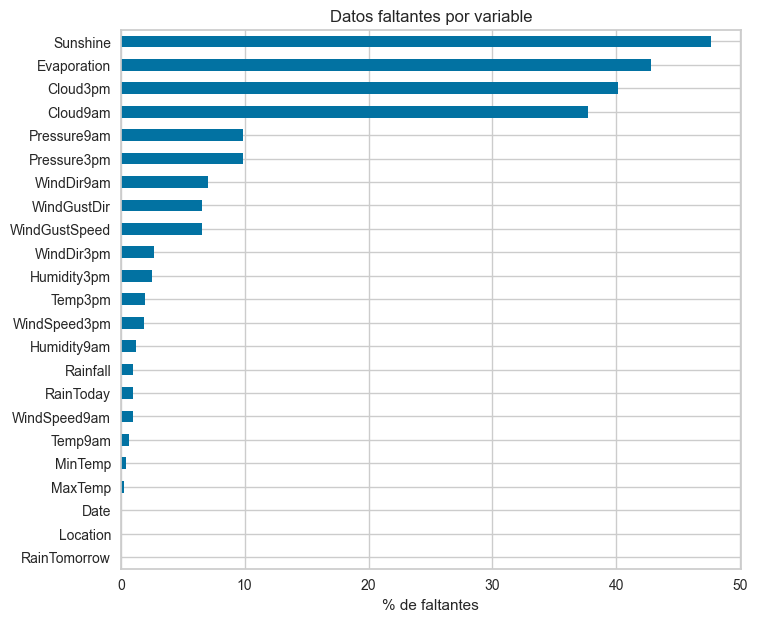

Sunshine         47.7
Evaporation      42.8
Cloud3pm         40.2
Cloud9am         37.7
Pressure9am       9.9
Pressure3pm       9.8
WindDir9am        7.0
WindGustDir       6.6
WindGustSpeed     6.5
WindDir3pm        2.7
Humidity3pm       2.5
Temp3pm           1.9
WindSpeed3pm      1.8
Humidity9am       1.2
Rainfall          1.0
RainToday         1.0
WindSpeed9am      0.9
Temp9am           0.6
MinTemp           0.4
MaxTemp           0.2
Date              0.0
Location          0.0
RainTomorrow      0.0
dtype: float64


In [12]:
# porcentaje de datos faltantes por columna
faltantes = (df.isna().mean() * 100).sort_values(ascending=False)
faltantes.plot.barh(figsize=(8, 7))
plt.xlabel("% de faltantes")
plt.gca().invert_yaxis()
plt.title("Datos faltantes por variable")
plt.show()
print(faltantes.round(1))

In [13]:
# porcentaje de datos faltantes de las variables con más NaN, según la ciudad (algunas estaciones no miden ciertas variables)
col_chequeo = faltantes.index[0]
por_ciudad = df.groupby("Location")[col_chequeo].apply(lambda s: s.isna().mean() * 100).sort_values(ascending=False)
print("% de faltantes de", col_chequeo, "por ciudad (top 10):")
print(por_ciudad.head(10).round(1))

% de faltantes de Sunshine por ciudad (top 10):
Location
Newcastle      100.0
Walpole        100.0
NorahHead      100.0
Penrith        100.0
Richmond       100.0
SalmonGums     100.0
Launceston     100.0
Katherine      100.0
Tuggeranong    100.0
GoldCoast      100.0
Name: Sunshine, dtype: float64


In [14]:
# diagnóstico: cómo faltan Sunshine y WindDir9am
sun_ciudad = df.groupby("Location")["Sunshine"].apply(lambda s: s.isna().mean() * 100)
print("Ciudades donde Sunshine falta en el 100% de los días:", (sun_ciudad == 100).sum(), "de", df["Location"].nunique())

dir_nan = df["WindDir9am"].isna()
sin_viento = df["WindSpeed9am"] == 0
print("\nWindDir9am faltante:", dir_nan.sum())
print("  de esos, con WindSpeed9am == 0 (sin viento):", (dir_nan & sin_viento).sum())
print("Días con WindSpeed9am == 0:", sin_viento.sum(), "| de esos, sin dirección registrada:", (dir_nan & sin_viento).sum())

Ciudades donde Sunshine falta en el 100% de los días: 19 de 49

WindDir9am faltante: 10009
  de esos, con WindSpeed9am == 0 (sin viento): 5931
Días con WindSpeed9am == 0: 6237 | de esos, sin dirección registrada: 5931


**Decisión sobre faltantes**

- Las variables con más del 40% de faltantes se eliminan: imputar casi la mitad de una columna con un valor constante agrega más ruido que información. Además los faltantes no son aleatorios, hay ciudades que no miden algunas variables.
- Con ese umbral quedarían `Sunshine`, `Evaporation` y `Cloud3pm`. Se eliminan `Evaporation` y `Cloud3pm`. `Cloud9am` queda justo por debajo (cerca de 38%) y se conserva.
- **`Sunshine` no se elimina.** Es una de las variables más relacionadas con la lluvia (ver matriz de correlación), así que descartarla es perder información. Falta por completo en varias ciudades, por eso no sirve rellenarla con una constante: se estima a partir de las demás variables con `IterativeImputer`, el mismo tipo de imputación que usa PyCaret con `imputation_type='iterative'`.
- `WindDir9am` y `WindDir3pm`: casi todos los días con velocidad de viento 0 no tienen dirección registrada. Cuando no hay viento no hay dirección, así que no se imputan con la moda (quedarían como viento del norte): se les asigna una categoría `"Calma"`.
- Las categóricas restantes se imputan con la moda de train.
- La imputación se hace después de separar train/val/test, ajustando todo solo con train.

In [15]:
# se define el umbral de faltantes y qué columnas se eliminan
UMBRAL_FALTANTES = 40
COLS_A_RECUPERAR = ["Sunshine"]  # superan el umbral, pero se estiman en lugar de eliminarlas
cols_a_eliminar = [c for c in faltantes[faltantes > UMBRAL_FALTANTES].index if c not in COLS_A_RECUPERAR]
print("Columnas a eliminar:", cols_a_eliminar)
print("Columnas a recuperar:", COLS_A_RECUPERAR)

Columnas a eliminar: ['Evaporation', 'Cloud3pm']
Columnas a recuperar: ['Sunshine']


### Visualización de datos

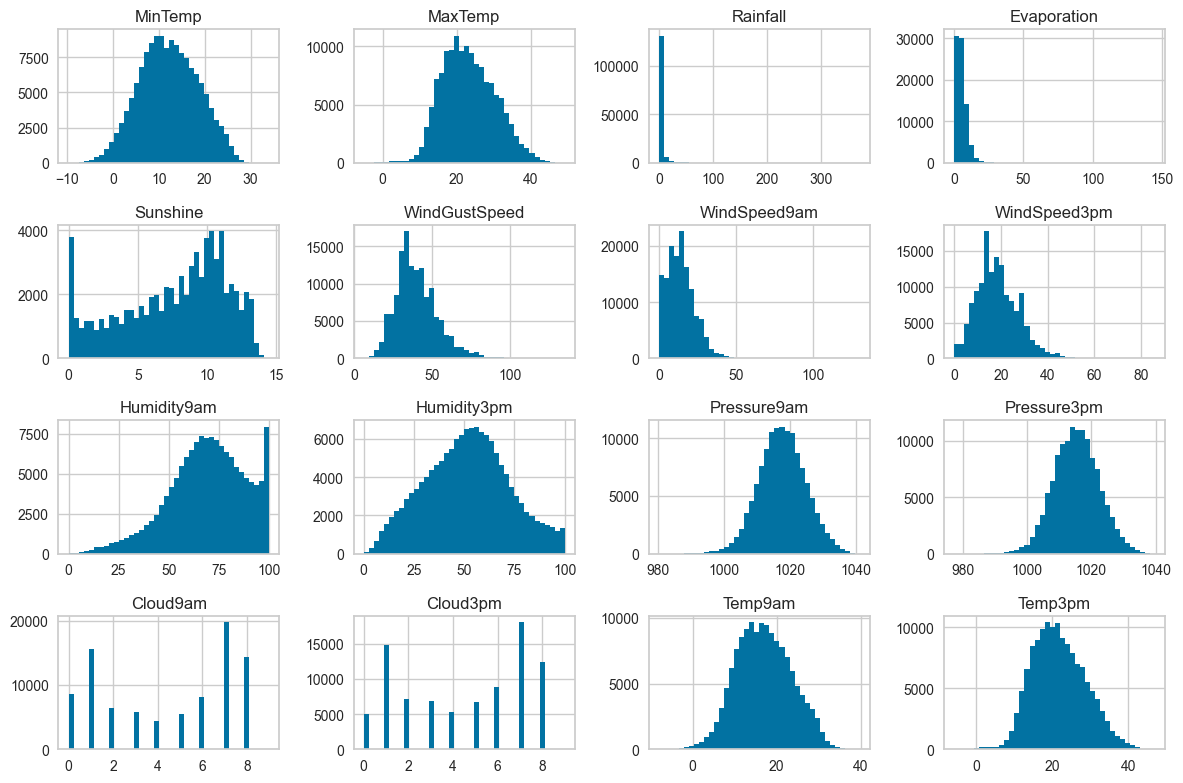

In [16]:
# histogramas de las variables numéricas
cols_numericas_eda = df.select_dtypes("number").columns.drop("RainTomorrow")
df[cols_numericas_eda].hist(bins=40, figsize=(12, 8))
plt.tight_layout()
plt.show()

Se ve que `Rainfall` y `Evaporation` tienen una distribución muy asimétrica a la derecha. Las temperaturas y la presión son bastante simétricas, y las humedades tienen forma más irregular. `Cloud` toma valores enteros de 0 a 8.

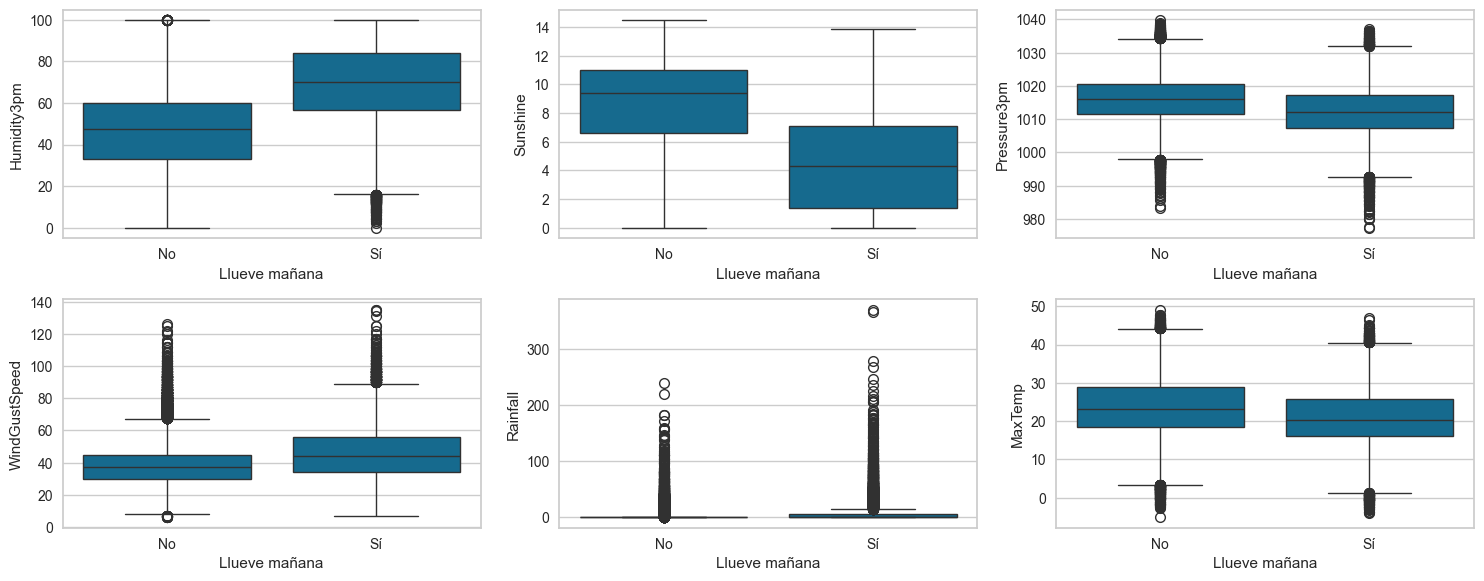

In [17]:
# boxplots de algunas variables según si llueve o no mañana
vars_box = ["Humidity3pm", "Sunshine", "Pressure3pm", "WindGustSpeed", "Rainfall", "MaxTemp"]
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, v in zip(axes.ravel(), vars_box):
    sns.boxplot(data=df, x="RainTomorrow", y=v, ax=ax)
    ax.set_xticklabels(["No", "Sí"])
    ax.set_xlabel("Llueve mañana")
plt.tight_layout()
plt.show()

Los días previos a una lluvia tienen mayor humedad a las 3pm, menos horas de sol, presión algo más baja y ráfagas más fuertes. `Rainfall` muestra muchos outliers, pero son valores reales (días de tormenta), por eso no los eliminamos.

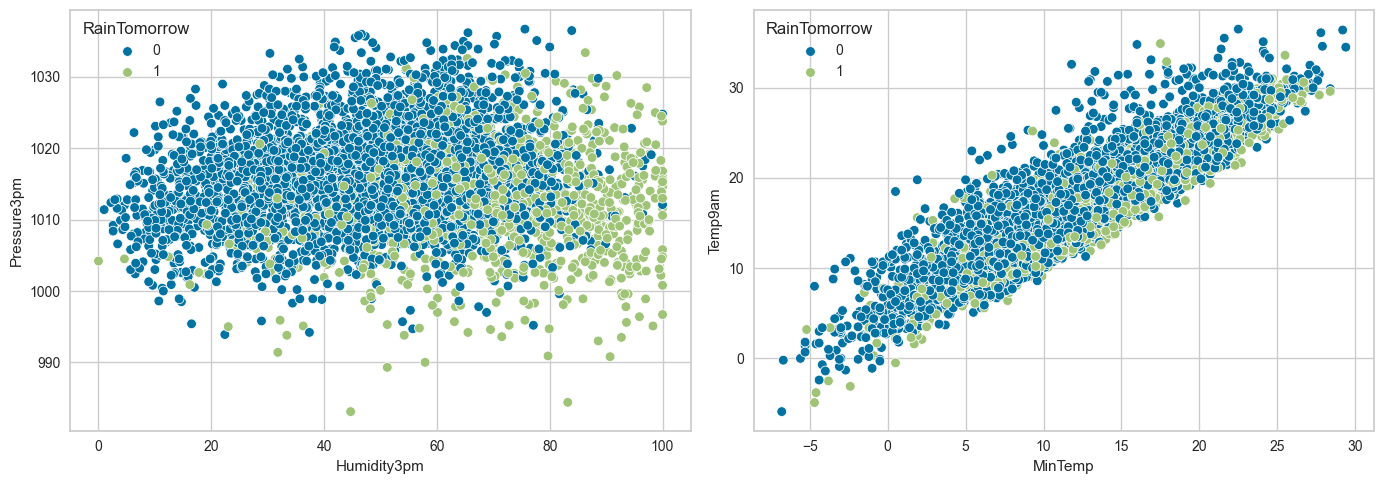

In [18]:
# scatterplots entre variables, usando una muestra para que se vea mejor
muestra = df.sample(5000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=muestra, x="Humidity3pm", y="Pressure3pm", hue="RainTomorrow", ax=axes[0])
sns.scatterplot(data=muestra, x="MinTemp", y="Temp9am", hue="RainTomorrow", ax=axes[1])
plt.tight_layout()
plt.show()

En el primer gráfico los días de lluvia se concentran con humedad alta y presión baja, aunque hay bastante solapamiento entre clases (el problema no es separable con una recta perfecta). El segundo muestra que `MinTemp` y `Temp9am` están muy relacionadas, algo que vamos a confirmar con la matriz de correlación.

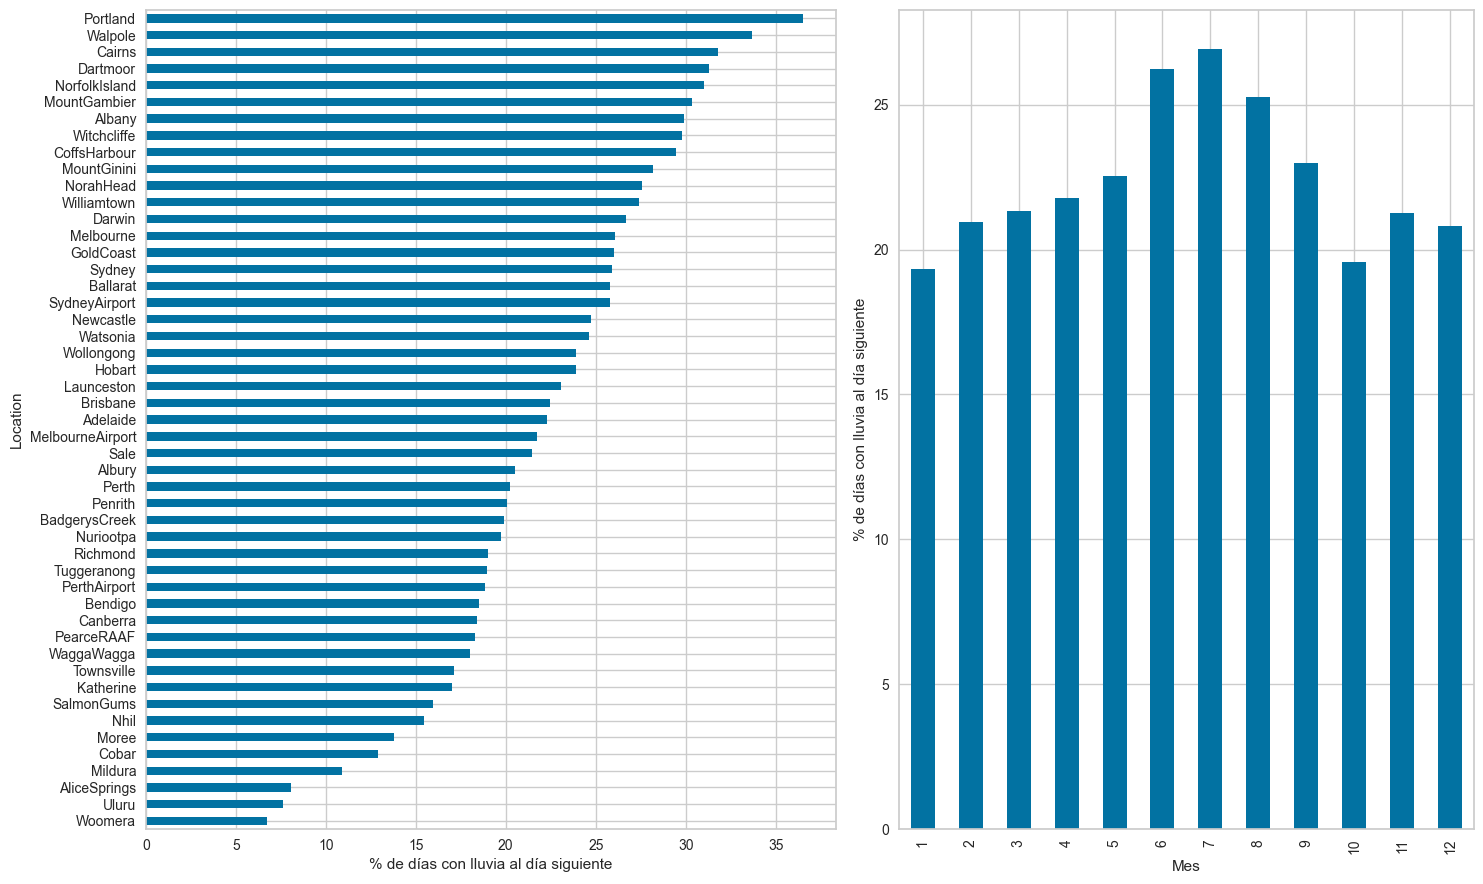

In [19]:
# proporción de días con lluvia por ciudad y por mes
fig, axes = plt.subplots(1, 2, figsize=(15, 9), gridspec_kw={"width_ratios": [1.2, 1]})
(df.groupby("Location")["RainTomorrow"].mean().sort_values() * 100).plot.barh(ax=axes[0])
axes[0].set_xlabel("% de días con lluvia al día siguiente")
(df.groupby(df["Date"].dt.month)["RainTomorrow"].mean() * 100).plot.bar(ax=axes[1])
axes[1].set_xlabel("Mes")
axes[1].set_ylabel("% de días con lluvia al día siguiente")
plt.tight_layout()
plt.show()

La probabilidad de lluvia cambia mucho según la ciudad y también según el mes, así que `Location` y la época del año aportan información. Por eso vamos a incluir la ubicación de la ciudad (como latitud y longitud) y construir una variable de mes a partir de `Date`.

### ¿Está balanceado el dataset?

RainTomorrow
0    110281
1     31872
Name: count, dtype: int64
RainTomorrow
0    77.58
1    22.42
Name: proportion, dtype: float64


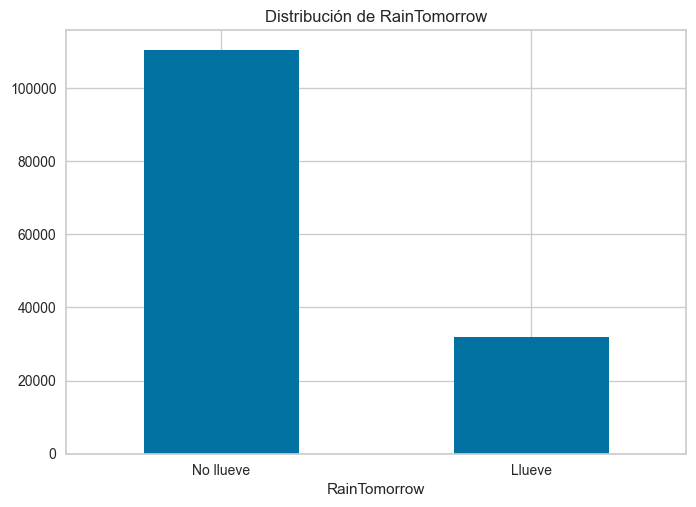

In [20]:
# cantidad y porcentaje de cada clase del target
conteo = df["RainTomorrow"].value_counts()
print(conteo)
print((df["RainTomorrow"].value_counts(normalize=True) * 100).round(2))
conteo.plot.bar()
plt.xticks([0, 1], ["No llueve", "Llueve"], rotation=0)
plt.title("Distribución de RainTomorrow")
plt.show()

El dataset **no está balanceado**: la clase "No llueve" es claramente la mayoritaria. Hacemos esta pregunta porque con clases desbalanceadas la *exactitud* engaña: un modelo que siempre responde "no llueve" tendría una exactitud alta sin haber aprendido nada. Por eso necesitamos métricas como recall, precision, F1 o AUC-PR, y por eso la separación train/val/test se hace para mantener la proporción de clases en cada conjunto. También vamos a probar `class_weight="balanced"` en la regresión logística.

### Matriz de correlación

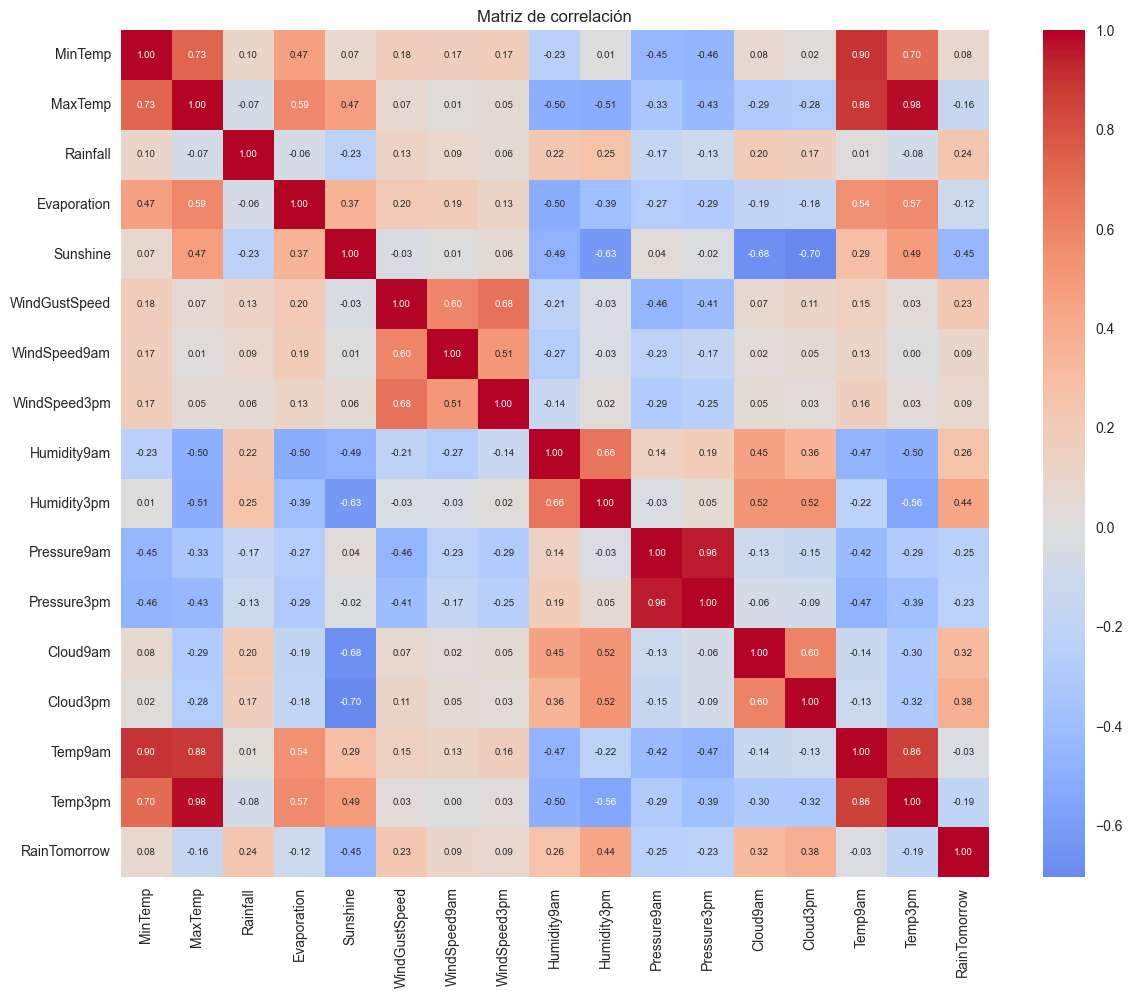

In [21]:
# matriz de correlación de las variables numéricas (incluyendo el target)
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Matriz de correlación")
plt.show()

In [22]:
# relaciones de variables con multicolinealidad
for col in corr.columns:
    for col2 in corr.columns:
        if col < col2 and abs(corr.loc[col, col2]) > 0.8:
            print(col, "-", col2, ":", round(corr.loc[col, col2], 2))

MinTemp - Temp9am : 0.9
MaxTemp - Temp9am : 0.88
MaxTemp - Temp3pm : 0.98
Pressure3pm - Pressure9am : 0.96
Temp3pm - Temp9am : 0.86


- Hay grupos de variables muy correlacionadas entre sí: las temperaturas (`MinTemp`, `MaxTemp`, `Temp9am`, `Temp3pm`) y las presiones de las 9am y 3pm. Esto es esperable porque miden casi lo mismo a distintas horas.
- Las variables más correlacionadas con el target son `Humidity3pm` (positiva) y `Sunshine` (negativa), seguidas por las nubosidades, `Humidity9am` y las presiones (negativa).
- Decidimos **no eliminar** las variables correlacionadas por ahora: la regresión logística con regularización L2 (la de por defecto) soporta bien la multicolinealidad.

### Preparación de variables

- `Date` se reemplaza por el mes, con seno y coseno (es cíclico: diciembre queda cerca de enero).
- `RainToday` se pasa a 0/1.
- Las direcciones de viento (16 puntos) también son cíclicas: se pasan a ángulo y de ahí a seno y coseno. Los días sin viento (`"Calma"`) no tienen ángulo y quedan con seno = 0 y coseno = 0.
- `Location` se reemplaza por su latitud y longitud. Son 2 columnas en lugar de 49 dummies, el modelo puede aprovechar que las ciudades cercanas tienen clima parecido, y en SHAP la ubicación no queda repartida en 49 columnas.

In [23]:
# se crean las variables de mes (cíclicas), se pasa RainToday a 0/1 y se elimina lo que no se usa
df["Month"] = df["Date"].dt.month
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)
df["RainToday"] = df["RainToday"].map({"No": 0, "Yes": 1})

df_model = df.drop(columns=cols_a_eliminar + ["Date", "Month"])
df_model.columns.tolist()

['Location',
 'MinTemp',
 'MaxTemp',
 'Rainfall',
 'Sunshine',
 'WindGustDir',
 'WindGustSpeed',
 'WindDir9am',
 'WindDir3pm',
 'WindSpeed9am',
 'WindSpeed3pm',
 'Humidity9am',
 'Humidity3pm',
 'Pressure9am',
 'Pressure3pm',
 'Cloud9am',
 'Temp9am',
 'Temp3pm',
 'RainToday',
 'RainTomorrow',
 'Month_sin',
 'Month_cos']

In [24]:
# ciudad -> latitud y longitud (coordenadas aproximadas de cada estación, en grados)
# es una tabla fija que no depende de los datos, así que se puede aplicar antes de separar sin filtrar información
COORDENADAS = {
    "Adelaide": (-34.93, 138.6),
    "Albany": (-35.02, 117.88),
    "Albury": (-36.08, 146.92),
    "AliceSprings": (-23.7, 133.88),
    "BadgerysCreek": (-33.88, 150.74),
    "Ballarat": (-37.56, 143.85),
    "Bendigo": (-36.76, 144.28),
    "Brisbane": (-27.47, 153.03),
    "Cairns": (-16.92, 145.77),
    "Canberra": (-35.28, 149.13),
    "Cobar": (-31.5, 145.83),
    "CoffsHarbour": (-30.3, 153.11),
    "Dartmoor": (-37.92, 141.28),
    "Darwin": (-12.46, 130.84),
    "GoldCoast": (-28.02, 153.4),
    "Hobart": (-42.88, 147.33),
    "Katherine": (-14.47, 132.26),
    "Launceston": (-41.44, 147.14),
    "Melbourne": (-37.81, 144.96),
    "MelbourneAirport": (-37.67, 144.84),
    "Mildura": (-34.19, 142.16),
    "Moree": (-29.46, 149.84),
    "MountGambier": (-37.83, 140.78),
    "MountGinini": (-35.53, 148.77),
    "Newcastle": (-32.93, 151.78),
    "Nhil": (-36.33, 141.65),
    "NorahHead": (-33.28, 151.57),
    "NorfolkIsland": (-29.03, 167.95),
    "Nuriootpa": (-34.47, 138.99),
    "PearceRAAF": (-31.67, 116.02),
    "Penrith": (-33.75, 150.69),
    "Perth": (-31.95, 115.86),
    "PerthAirport": (-31.94, 115.97),
    "Portland": (-38.35, 141.6),
    "Richmond": (-33.6, 150.75),
    "Sale": (-38.1, 147.07),
    "SalmonGums": (-32.98, 121.64),
    "Sydney": (-33.87, 151.21),
    "SydneyAirport": (-33.95, 151.18),
    "Townsville": (-19.26, 146.82),
    "Tuggeranong": (-35.42, 149.09),
    "Uluru": (-25.34, 131.04),
    "WaggaWagga": (-35.12, 147.37),
    "Walpole": (-34.98, 116.73),
    "Watsonia": (-37.71, 145.08),
    "Williamtown": (-32.8, 151.84),
    "Witchcliffe": (-34.03, 115.1),
    "Wollongong": (-34.43, 150.89),
    "Woomera": (-31.2, 136.82),
}

faltan_coord = set(df_model["Location"].unique()) - set(COORDENADAS)
assert not faltan_coord, f"ciudades sin coordenadas: {faltan_coord}"

df_model["Lat"] = df_model["Location"].map(lambda c: COORDENADAS[c][0])
df_model["Lon"] = df_model["Location"].map(lambda c: COORDENADAS[c][1])
df_model = df_model.drop(columns="Location")
df_model[["Lat", "Lon"]].describe().round(2)

,Lat,Lon
count,142153.00,142153.00
mean,-32.75,142.09
std,6.03,12.08
min,-42.88,115.10
25%,-36.08,138.60
50%,-33.95,145.83
75%,-31.50,150.74
max,-12.46,167.95


In [25]:
# se agrupan las columnas según el tratamiento que va a recibir cada una
cols_viento = [c for c in ["WindGustDir", "WindDir9am", "WindDir3pm"] if c in df_model.columns]
cols_ciclicas = ["Month_sin", "Month_cos"]
cols_cat = cols_viento + ["RainToday"]
cols_num = [c for c in df_model.columns
            if c not in cols_cat + cols_ciclicas + ["RainTomorrow"]]
print("Numéricas continuas:", cols_num)
print("Categóricas:", cols_cat)

Numéricas continuas: ['MinTemp', 'MaxTemp', 'Rainfall', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Temp9am', 'Temp3pm', 'Lat', 'Lon']
Categóricas: ['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']


### Separación en train, validación y test

Separamos antes de imputar y escalar, para que ningún estadístico se calcule con datos que el modelo no debería ver. Usamos 60% entrenamiento, 20% validación y 20% test, siempre estratificado por el target.

- **Train**: ajusta el modelo, los imputers y el scaler.
- **Validación**: se usa para comparar modelos y elegir el umbral de decisión.
- **Test**: se toca solo al final, para reportar el desempeño.

In [26]:
# se separa test (20%) y luego validación (25% de lo que queda = 20% del total), estratificando por el target
X = df_model.drop(columns="RainTomorrow")
y = df_model["RainTomorrow"]

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=SEED)

for nombre, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(nombre, len(yy), "filas | % lluvia:", round(yy.mean() * 100, 2))

train 85291 filas | % lluvia: 22.42
val 28431 filas | % lluvia: 22.42
test 28431 filas | % lluvia: 22.42


### Imputación de faltantes

Todo se ajusta solo con train y se aplica a los tres conjuntos:
1. Direcciones de viento: si falta la dirección y la velocidad es 0, se completa con `"Calma"`.
2. Numéricas (incluida `Sunshine`): `IterativeImputer`, que estima cada columna con faltantes a partir de las demás. Para que los valores estimados no se salgan de rango (por ejemplo `Sunshine` negativa o humedad mayor a 100) se limitan al mínimo y máximo de train.
3. Categóricas restantes: moda de train.

In [27]:
# imputador iterativo para las numéricas (más el mes y RainToday como variables auxiliares), ajustado solo con train
cols_imp = cols_num + cols_ciclicas + ["RainToday"]
imputer_num = IterativeImputer(max_iter=10, random_state=SEED,
                               min_value=X_train[cols_imp].min().values,
                               max_value=X_train[cols_imp].max().values).fit(X_train[cols_imp])

# moda de las categóricas con train (los NaN no cuentan)
modas = X_train[cols_cat].mode().iloc[0]

def imputar(X_):
    X_ = X_.copy()
    # sin viento no hay dirección: se marca como "Calma" en vez de usar la moda
    for dir_col, vel_col in [("WindDir9am", "WindSpeed9am"), ("WindDir3pm", "WindSpeed3pm")]:
        if dir_col in X_.columns:
            X_.loc[X_[dir_col].isna() & (X_[vel_col] == 0), dir_col] = "Calma"
    # numéricas: las primeras len(cols_num) columnas del resultado son las de cols_num
    X_[cols_num] = imputer_num.transform(X_[cols_imp])[:, :len(cols_num)]
    X_[cols_cat] = X_[cols_cat].fillna(modas)
    return X_

X_train_imp = imputar(X_train)
X_val_imp = imputar(X_val)
X_test_imp = imputar(X_test)
print("Faltantes restantes en train:", X_train_imp.isna().sum().sum())
print("Días 'Calma' en train: 9am =", (X_train_imp["WindDir9am"] == "Calma").sum(), "| 3pm =", (X_train_imp["WindDir3pm"] == "Calma").sum())

Faltantes restantes en train: 0
Días 'Calma' en train: 9am = 3580 | 3pm = 467


### Codificación de variables categóricas

Las direcciones de viento pasan a seno y coseno de su ángulo. `"Calma"` no tiene ángulo, así que queda en (0, 0): no apunta a ninguna dirección. La ciudad ya está representada por `Lat` y `Lon`, no hace falta one-hot.

In [28]:
# direcciones de viento a ángulo (16 puntos cardinales, cada 22.5 grados)
direcciones = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
angulo = {d: i * 2 * np.pi / 16 for i, d in enumerate(direcciones)}

def codificar(X_):
    X_ = X_.copy()
    # viento: seno y coseno del ángulo; "Calma" no está en el diccionario -> NaN -> (0, 0) = sin dirección
    for c in cols_viento:
        ang = X_[c].map(angulo)
        X_[c + "_sin"] = np.sin(ang).fillna(0)
        X_[c + "_cos"] = np.cos(ang).fillna(0)
    return X_.drop(columns=cols_viento)

X_train_enc = codificar(X_train_imp)
columnas_finales = X_train_enc.columns
X_val_enc = codificar(X_val_imp)[columnas_finales]
X_test_enc = codificar(X_test_imp)[columnas_finales]
print("Cantidad de variables de entrada:", len(columnas_finales))

Cantidad de variables de entrada: 25


### Estandarización

Escalamos solo las variables numéricas continuas con `StandardScaler` (media 0, desvío 1), ajustado con train. Es importante para la regresión logística con regularización, porque la penalización depende de la escala de los coeficientes, y también ayuda a que el solver converja. `Lat` y `Lon` son numéricas continuas y sí se escalan junto con el resto. `RainToday` y las variables seno/coseno ya están en rangos chicos y no se escalan.

In [29]:
# se ajusta el scaler con train y se transforman los tres conjuntos
scaler = StandardScaler().fit(X_train_enc[cols_num])

def escalar(X_):
    X_ = X_.copy()
    X_[cols_num] = scaler.transform(X_[cols_num])
    return X_

X_train_s = escalar(X_train_enc)
X_val_s = escalar(X_val_enc)
X_test_s = escalar(X_test_enc)
X_train_s[cols_num].describe().loc[["mean", "std"]].round(2)

,MinTemp,MaxTemp,Rainfall,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Temp9am,Temp3pm,Lat,Lon
mean,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 2. Regresión logística

Antes de entrenar, definimos funciones para calcular métricas y graficar, así se reutilizan con todos los modelos.

Las métricas que vamos a usar:
- **Accuracy**: proporción de aciertos. Poco confiable con clases desbalanceadas.
- **Precision**: de los días que predijimos lluvia, cuántos realmente llovieron.
- **Recall**: de los días que realmente llovieron, cuántos detectamos.
- **F1**: media armónica entre precision y recall.
- **Balanced accuracy**: promedio del recall de cada clase.
- **MCC** (Matthews): correlación entre predicción y realidad, usa los cuatro valores de la matriz de confusión y sirve con clases desbalanceadas.
- **ROC AUC** y **PR AUC** (average precision): miden la calidad del ranking de probabilidades sin depender de un umbral. La PR AUC es más exigente cuando la clase positiva es minoritaria.

In [30]:
# funciones para calcular métricas y graficar matrices de confusión
def metricas(y_true, proba, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Balanced Acc": balanced_accuracy_score(y_true, pred),
        "MCC": matthews_corrcoef(y_true, pred),
        "ROC AUC": roc_auc_score(y_true, proba),
        "PR AUC": average_precision_score(y_true, proba),
    }

def graficar_cm(ax, y_true, proba, titulo, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_true, pred, display_labels=["No llueve", "Llueve"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(titulo)
    ax.grid(False)

In [31]:
# se entrena la regresión logística común y otra con class_weight="balanced"
logreg = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_s, y_train)
logreg_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED).fit(X_train_s, y_train)

# probabilidades de la clase "llueve" en cada conjunto
proba = {
    "LogReg": {"train": logreg.predict_proba(X_train_s)[:, 1],
               "val": logreg.predict_proba(X_val_s)[:, 1],
               "test": logreg.predict_proba(X_test_s)[:, 1]},
    "LogReg balanced": {"train": logreg_bal.predict_proba(X_train_s)[:, 1],
                        "val": logreg_bal.predict_proba(X_val_s)[:, 1],
                        "test": logreg_bal.predict_proba(X_test_s)[:, 1]},
}
y_por_set = {"train": y_train, "val": y_val, "test": y_test}

In [32]:
# métricas en train y validación (umbral 0.5) para ver si hay sobreajuste
filas = {}
for modelo in ["LogReg", "LogReg balanced"]:
    for s in ["train", "val"]:
        filas[(modelo, s)] = metricas(y_por_set[s], proba[modelo][s])
tabla_lr = pd.DataFrame(filas).T
tabla_lr.round(3)

Accuracy  Precision  Recall     F1  Balanced Acc  \
LogReg          train     0.846      0.722   0.511  0.598         0.727   
                val       0.843      0.714   0.497  0.586         0.720   
LogReg balanced train     0.791      0.523   0.772  0.624         0.785   
                val       0.791      0.523   0.771  0.623         0.784   

                         MCC  ROC AUC  PR AUC  
LogReg          train  0.518    0.868   0.695  
                val    0.505    0.867   0.687  
LogReg balanced train  0.504    0.869   0.692  
                val    0.504    0.867   0.685

Las métricas de train y validación son muy parecidas, así que no hay sobreajuste. Entre la regresión logística común y la balanceada se ve el trade-off esperable: la balanceada sube el recall (detecta más días de lluvia) a costa de bajar la precision y la accuracy. Los AUC prácticamente no cambian, porque `class_weight` no modifica el ranking de las probabilidades de forma importante, solo desplaza el punto de corte efectivo.

In [33]:
y_pred1 = (proba["LogReg"]["val"] >= 0.5).astype(int)
print(pd.crosstab(y_val, y_pred1))

y_pred2 = (proba["LogReg balanced"]["val"] >= 0.5).astype(int)
print(pd.crosstab(y_val, y_pred2))

col_0             0     1
RainTomorrow             
0             20788  1268
1              3209  3166
col_0             0     1
RainTomorrow             
0             17572  4484
1              1457  4918


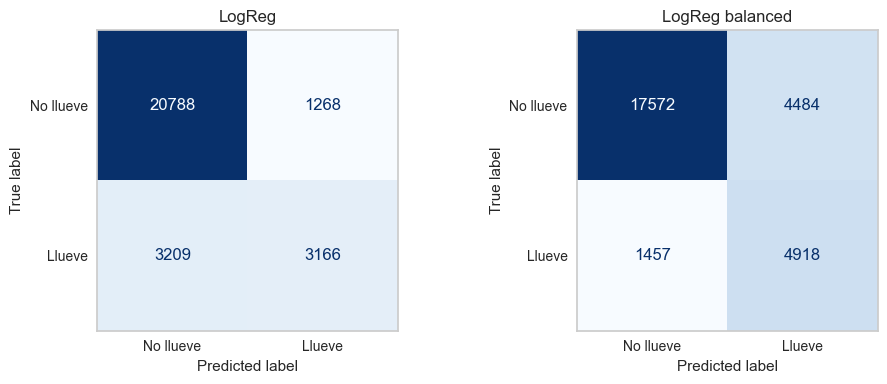

In [34]:
# matrices de confusión en validación de cada modelo (umbral 0.5)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
graficar_cm(axes[0], y_val, proba["LogReg"]["val"], "LogReg")
graficar_cm(axes[1], y_val, proba["LogReg balanced"]["val"], "LogReg balanced")
plt.tight_layout()
plt.show()

**Falsos positivos y falsos negativos**

- **Falso positivo (FP)**: el modelo dice "llueve" y no llovió. La consecuencia es una falsa alarma: llevar paraguas de más, suspender una actividad que se podía hacer.
- **Falso negativo (FN)**: el modelo dice "no llueve" y llovió. Es el error más costoso en la mayoría de los casos prácticos (cosecha sin cubrir, evento al aire libre sin plan B, mojarse).

Como creemos que el FN es más costoso, nos interesa priorizar el **recall** de la clase "llueve" sin que la precision caiga demasiado, y por eso miramos el F1 y no solo la accuracy. La regresión logística común comete muchos FN, que es lo que se ve en la matriz.

### Curva ROC y umbral de decisión

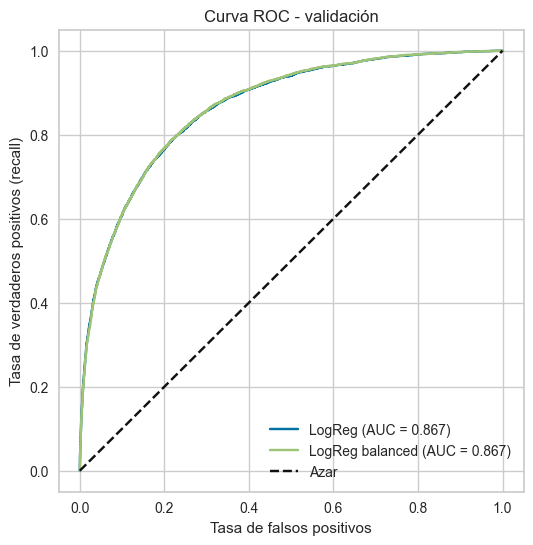

In [35]:
# curvas ROC en validación
plt.figure(figsize=(6, 6))
for modelo in ["LogReg", "LogReg balanced"]:
    fpr, tpr, _ = roc_curve(y_val, proba[modelo]["val"])
    plt.plot(fpr, tpr, label=f"{modelo} (AUC = {roc_auc_score(y_val, proba[modelo]['val']):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curva ROC - validación")
plt.legend()
plt.show()

En una curva ROC cada punto es un umbral distinto: con umbrales bajos nos movemos hacia arriba y a la derecha (se detectan más días de lluvia, pero también hay más falsas alarmas) y con umbrales altos hacia abajo y a la izquierda.

- Las dos curvas se superponen casi por completo y tienen el mismo AUC (0.867). Es esperable: `class_weight='balanced'` modifica las probabilidades, pero casi no cambia el orden en que el modelo ordena los días.
- Las dos quedan muy por encima de la diagonal (el azar, AUC = 0.5) y suben rápido: con un 20% de falsas alarmas (FPR = 0.2) ya se detecta alrededor del 77% de los días de lluvia (TPR). Por eso el AUC es alto y el modelo ordena bastante bien los días de lluvia respecto de los que no.

**¿Es 0.5 el mejor umbral?** No tiene por qué. La curva no dice cuál es el mejor umbral, solo muestra qué combinaciones de TPR y FPR se pueden conseguir. El 0.5 es solo el valor por defecto y funciona bien cuando las clases están balanceadas y los errores cuestan lo mismo. Acá no pasa ninguna de las dos cosas. Dos formas de elegir el umbral:
1. **Índice de Youden**: el punto de la ROC que maximiza `TPR - FPR`.
2. **Maximizar el F1** sobre la curva precision-recall.

Los umbrales se eligen con el conjunto de **validación** (nunca con test, para no sesgar la evaluación final).

In [36]:
# se busca el umbral óptimo en validación con Youden y con F1 máximo
def mejores_umbrales(y_true, p):
    fpr, tpr, thr = roc_curve(y_true, p)
    umbral_youden = thr[np.argmax(tpr - fpr)]
    prec, rec, thr_pr = precision_recall_curve(y_true, p)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    umbral_f1 = thr_pr[np.argmax(f1s)]
    return umbral_youden, umbral_f1

umbrales = {}
for modelo in ["LogReg", "LogReg balanced"]:
    umbrales[modelo] = mejores_umbrales(y_val, proba[modelo]["val"])
    print(f"{modelo}: umbral Youden = {umbrales[modelo][0]:.3f} | umbral F1 máx = {umbrales[modelo][1]:.3f}")

LogReg: umbral Youden = 0.201 | umbral F1 máx = 0.282
LogReg balanced: umbral Youden = 0.485 | umbral F1 máx = 0.561


In [37]:
# se compara en validación el umbral 0.5 con los umbrales óptimos (regresión logística común)
p_val = proba["LogReg"]["val"]
comp = pd.DataFrame({
    "0.5": metricas(y_val, p_val, 0.5),
    "Youden": metricas(y_val, p_val, umbrales["LogReg"][0]),
    "F1 máx": metricas(y_val, p_val, umbrales["LogReg"][1]),
}).T
comp.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
0.5,0.843,0.714,0.497,0.586,0.720,0.505,0.867,0.687
Youden,0.777,0.502,0.798,0.616,0.785,0.496,0.867,0.687
F1 máx,0.816,0.572,0.708,0.633,0.777,0.517,0.867,0.687


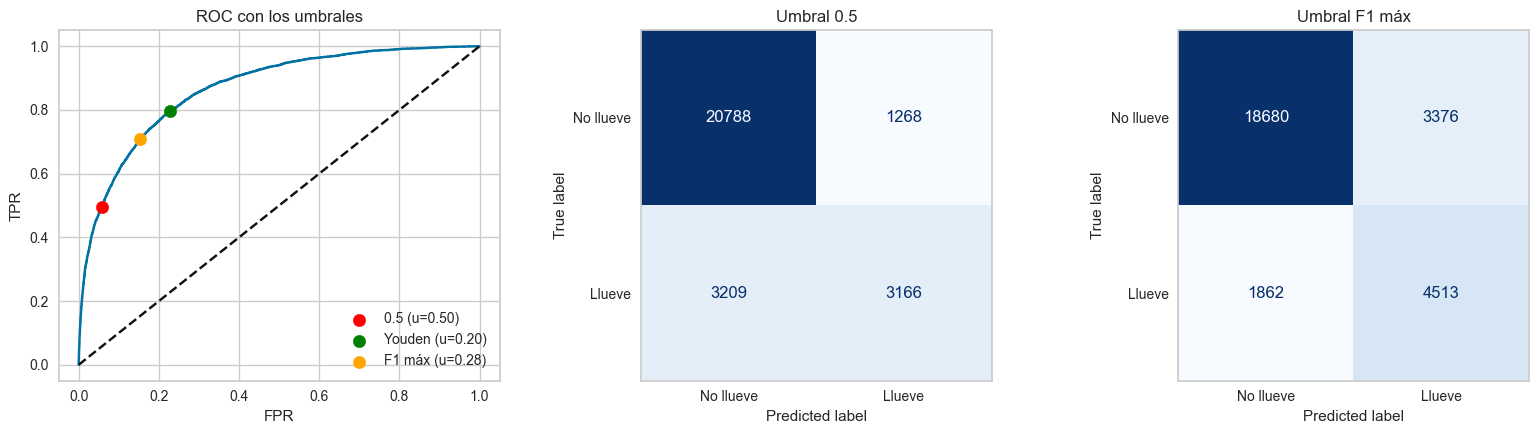

In [38]:
# punto de cada umbral sobre la curva ROC y matrices de confusión con cada umbral
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fpr, tpr, _ = roc_curve(y_val, p_val)
axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], "k--")
for nombre, u, c in [("0.5", 0.5, "red"), ("Youden", umbrales["LogReg"][0], "green"), ("F1 máx", umbrales["LogReg"][1], "orange")]:
    pred = (p_val >= u).astype(int)
    f = ((pred == 1) & (y_val == 0)).sum() / (y_val == 0).sum()
    t = ((pred == 1) & (y_val == 1)).sum() / (y_val == 1).sum()
    axes[0].scatter(f, t, color=c, s=80, zorder=3, label=f"{nombre} (u={u:.2f})")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].set_title("ROC con los umbrales")
axes[0].legend()
graficar_cm(axes[1], y_val, p_val, "Umbral 0.5")
graficar_cm(axes[2], y_val, p_val, "Umbral F1 máx", umbral=umbrales["LogReg"][1])
plt.tight_layout()
plt.show()

En el gráfico de la izquierda, el punto rojo (umbral 0.5) queda abajo a la izquierda: pocas falsas alarmas (FPR cerca de 0.06) pero se detecta solo la mitad de los días de lluvia (TPR cerca de 0.50). Al bajar el umbral nos movemos hacia arriba y a la derecha: con 0.28 (F1 máx) el TPR sube a 0.71 y el FPR a 0.15, y con 0.20 (Youden) el TPR llega a 0.80 y el FPR a 0.23.

Las matrices de confusión lo confirman: al pasar de 0.5 a 0.28 los falsos negativos bajan de 3209 a 1862, a cambio de que las falsas alarmas suban de 1268 a 3376. Como creemos que un falso negativo es peor que una falsa alarma, el cambio tiene sentido, y el F1 en validación pasa de 0.586 a 0.633.

Youden da el mismo peso a las tasas de FP y FN y, como solo llueve cerca del 22% de los días, termina generando muchas falsas alarmas (precision de 0.50), por eso su F1 (0.616) queda por debajo del de F1 máx, que se enfoca en la clase positiva. Si se conociera el costo real de cada error, el umbral se podría elegir minimizando el costo esperado.

El modelo balanceado llega a algo parecido por otro camino: sus mejores umbrales quedan cerca de 0.5 (0.49 y 0.56) porque `class_weight` ya desplazó sus probabilidades hacia arriba. Por eso las curvas ROC de ambos modelos son iguales: cambia dónde queda el umbral, no el ranking.

Para el resto del trabajo usamos el **umbral que maximiza el F1 en validación** para clasificar. En cambio, para comparar modelos o buscar hiperparámetros sin depender de un umbral (como en el ítem 4) usamos la PR AUC.

In [39]:
# resultado final de la regresión logística en test, con el umbral 0.5 y con el umbral elegido
UMBRAL_LR = umbrales["LogReg"][1]
p_test = proba["LogReg"]["test"]
res_test_lr = pd.DataFrame({
    "LogReg (u=0.5)": metricas(y_test, p_test, 0.5),
    "LogReg (u=F1 máx)": metricas(y_test, p_test, UMBRAL_LR),
}).T
res_test_lr.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
LogReg (u=0.5),0.847,0.724,0.511,0.599,0.727,0.519,0.869,0.7
LogReg (u=F1 máx),0.818,0.575,0.717,0.638,0.782,0.524,0.869,0.7


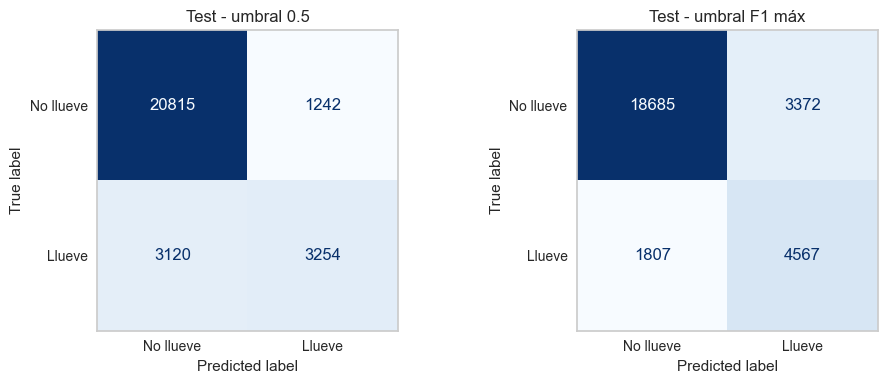

In [40]:
# matrices de confusión en test con ambos umbrales
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
graficar_cm(axes[0], y_test, p_test, "Test - umbral 0.5")
graficar_cm(axes[1], y_test, p_test, "Test - umbral F1 máx", umbral=UMBRAL_LR)
plt.tight_layout()
plt.show()

### ¿Conseguimos un buen fitting?

- **Sobreajuste**: no. Las métricas de train y validación son casi iguales, y test se comporta igual que validación.
- **Subajuste**: es posible que haya algo. La regresión logística es un modelo lineal, y el problema probablemente tenga interacciones y no linealidades que no captura (por ejemplo, el efecto combinado de humedad y presión). Además, con el umbral 0.5 el recall de la clase "llueve" es bajo.
- Aun así, es un buen punto de partida: el AUC es alto, el ajuste es estable y, con el umbral bien elegido, el balance entre precision y recall mejora bastante. Modelos más flexibles (los que vienen en los ítems siguientes) podrían mejorarlo.

## 3. Modelo base

Un modelo base sirve de piso: cualquier modelo más complejo tiene que superarlo para justificarse. Usamos tres:

1. **Dummy "siempre No"** (`most_frequent`): predice siempre la clase mayoritaria. Muestra lo que daría la accuracy sin aprender nada.
2. **Dummy estratificado**: predice al azar respetando la proporción de clases de train.
3. **Regla simple "mañana llueve si hoy llovió"**: usa solo `RainToday`. Es un baseline con sentido meteorológico y no usa ningún aprendizaje.

In [41]:
# se entrenan los dos modelos dummy y se arman las probabilidades de los tres baselines
dummy_mf = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
dummy_est = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_train_s, y_train)

def probas_base(X_s):
    return {
        "Base: siempre No": dummy_mf.predict_proba(X_s)[:, 1],
        "Base: azar estratificado": dummy_est.predict_proba(X_s)[:, 1],
        "Base: RainToday": X_s["RainToday"].values.astype(float),
    }

proba_base = {"train": probas_base(X_train_s), "val": probas_base(X_val_s), "test": probas_base(X_test_s)}

In [42]:
# métricas de los baselines en validación (umbral 0.5)
tabla_base = pd.DataFrame({m: metricas(y_val, p) for m, p in proba_base["val"].items()}).T
tabla_base.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
Base: siempre No,0.776,0.000,0.000,0.000,0.500,0.000,0.500,0.224
Base: azar estratificado,0.653,0.225,0.224,0.225,0.501,0.001,0.501,0.224
Base: RainToday,0.760,0.464,0.461,0.462,0.653,0.308,0.653,0.335


El "siempre No" tiene una accuracy parecida a la proporción de la clase mayoritaria pero recall 0 y F1 0: nunca detecta una lluvia. Esto confirma por qué la accuracy sola no sirve en este problema. El dummy estratificado queda en AUC de 0.5 (azar). La regla `RainToday` es el baseline más interesante: da un recall y un F1 que no son despreciables usando una sola variable, y es el valor a superar.

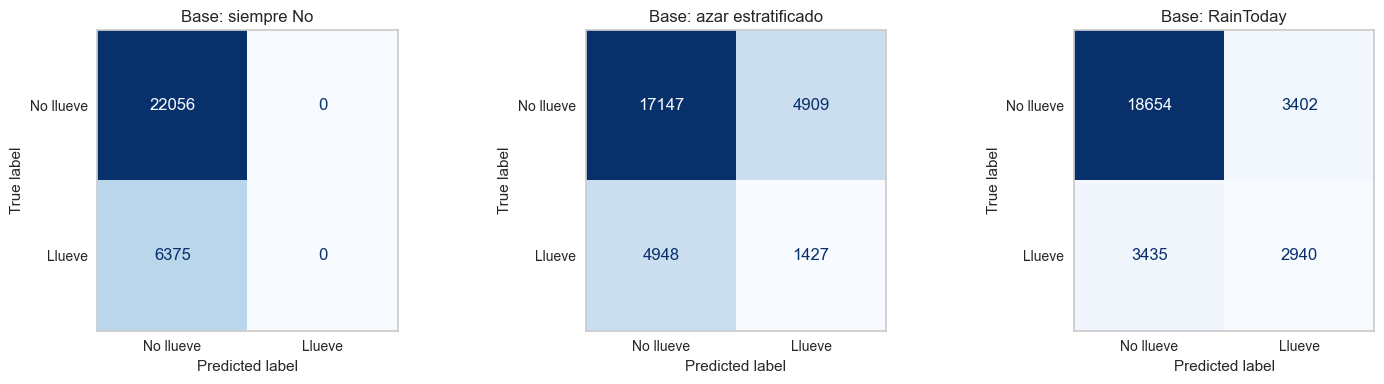

In [43]:
# matrices de confusión de los baselines en validación
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (m, p) in zip(axes, proba_base["val"].items()):
    graficar_cm(ax, y_val, p, m)
plt.tight_layout()
plt.show()

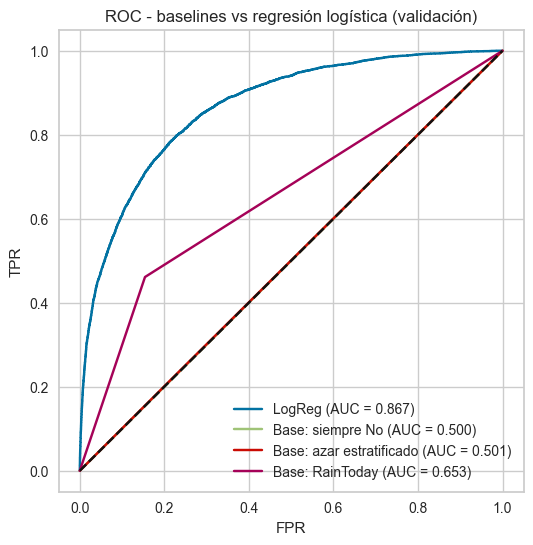

In [44]:
# curvas ROC de baselines y regresión logística en validación
plt.figure(figsize=(6, 6))
plt.plot(*roc_curve(y_val, proba["LogReg"]["val"])[:2], label=f"LogReg (AUC = {roc_auc_score(y_val, proba['LogReg']['val']):.3f})")
for m, p in proba_base["val"].items():
    plt.plot(*roc_curve(y_val, p)[:2], label=f"{m} (AUC = {roc_auc_score(y_val, p):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC - baselines vs regresión logística (validación)")
plt.legend()
plt.show()

Las curvas de los baselines con probabilidades constantes o binarias son rectas o puntos sobre la diagonal (o cerca), porque no hay un ranking real de probabilidades que recorrer. Por eso en los baselines no tiene sentido buscar un umbral: la regresión logística es la única con una curva ROC realmente por encima del azar.

### Comparación en test: baselines vs regresión logística

In [45]:
# tabla final de este entregable, evaluada en test
resultados_test = {
    "LogReg (u=0.5)": metricas(y_test, proba["LogReg"]["test"], 0.5),
    "LogReg (u=F1 máx)": metricas(y_test, proba["LogReg"]["test"], UMBRAL_LR),
    "LogReg balanced (u=0.5)": metricas(y_test, proba["LogReg balanced"]["test"], 0.5),
}
for m, p in proba_base["test"].items():
    resultados_test[m] = metricas(y_test, p)

tabla_final = pd.DataFrame(resultados_test).T.sort_values("F1", ascending=False)
tabla_final.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
LogReg (u=F1 máx),0.818,0.575,0.717,0.638,0.782,0.524,0.869,0.700
LogReg balanced (u=0.5),0.793,0.527,0.772,0.626,0.786,0.508,0.870,0.697
LogReg (u=0.5),0.847,0.724,0.511,0.599,0.727,0.519,0.869,0.700
Base: RainToday,0.757,0.458,0.455,0.456,0.649,0.300,0.649,0.330
Base: azar estratificado,0.656,0.230,0.229,0.229,0.504,0.008,0.504,0.226
Base: siempre No,0.776,0.000,0.000,0.000,0.500,0.000,0.500,0.224


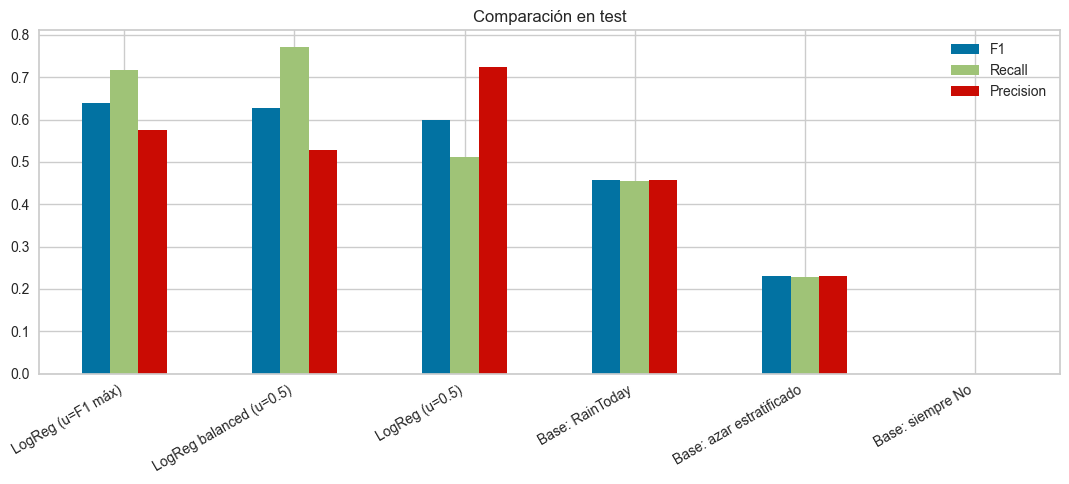

In [46]:
# gráfico de barras con F1 y recall de cada modelo en test
tabla_final[["F1", "Recall", "Precision"]].plot.bar(figsize=(11, 5))
plt.xticks(rotation=30, ha="right")
plt.title("Comparación en test")
plt.tight_layout()
plt.show()

**Conclusiones de la primera etapa**

- El dataset está desbalanceado, por lo que la accuracy no alcanza para evaluar: usamos F1, recall, MCC y AUC.
- La regresión logística supera claramente a todos los baselines en F1, MCC y AUC. Es decir, aprende algo más que "si hoy llovió, mañana llueve".
- El umbral 0.5 no es el mejor para este problema. Bajarlo (usando el F1 máximo en validación) mejora el balance entre precision y recall.
- El fitting es estable (train, validación y test parecidos), pero al ser un modelo lineal puede estar limitado.

## 4. Selección de hiperparámetros optimizada

Para la regresión logística optimizamos con `GridSearchCV` y validación cruzada de 5 folds estratificados, usando solo el conjunto de train (validación se usa para elegir el umbral y test para la evaluación final).

**Justificaciones:**
- Utilizamos **k-folds estratificado** porque mantiene la proporción de días de lluvia en cada fold, así que las métricas de cada fold son comparables.
- Utilizamos **grid search** porque son pocos hiperparámetros con pocos valores, entonces probar todas es barato y se puede ver el resultado completo. Random search u Optuna tienen más sentido con espacios grandes.
- **Hiperparámetros que se optimizan:**
  - `C`: inversa de la fuerza de regularización. Valores chicos penalizan más los coeficientes. Con variables muy correlacionadas (por ejemplo `Pressure9am` y `Pressure3pm`) la regularización estabiliza los coeficientes.
  - `penalty`: `l2` achica todos los coeficientes, `l1` puede llevar algunos a cero (elimina variables).
- **`class_weight` no se optimiza:** en la sección 2 vimos que no cambia el ranking de las probabilidades (el AUC es el mismo), solo mueve el umbral, y el umbral lo elegimos aparte en validación.
- **Métrica a optimizar:** `average_precision` (PR AUC). No depende del umbral y es adecuada con clases desbalanceadas. No usamos el F1 con umbral 0.5 porque después cambiamos el umbral. También calculamos ROC AUC y F1 para comparar.

In [47]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

param_grid = {
    "C": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
}

# se optimiza la PR AUC y se calculan también ROC AUC y F1
grid_search = GridSearchCV(
    estimator=LogisticRegression(solver="saga", max_iter=2000, random_state=SEED),
    param_grid=param_grid,
    scoring={"average_precision": "average_precision", "roc_auc": "roc_auc", "f1": "f1"},
    refit="average_precision",
    cv=kfold,
    n_jobs=5,
)
grid_search.fit(X_train_s, y_train)

print("Mejores hiperparámetros:", grid_search.best_params_)
print("PR AUC promedio en CV:", round(grid_search.best_score_, 4))

Mejores hiperparámetros: {'C': 0.1, 'penalty': 'l2'}
PR AUC promedio en CV: 0.6947


In [48]:
# resultados de la validación cruzada para cada combinación
res_cv = pd.DataFrame(grid_search.cv_results_)[["param_C", "param_penalty", "mean_test_average_precision",
                                                 "std_test_average_precision", "mean_test_roc_auc", "mean_test_f1"]]
res_cv.columns = ["C", "penalty", "PR AUC (media)", "PR AUC (desvío)", "ROC AUC (media)", "F1 (media)"]
res_cv.round(4)

,C,penalty,PR AUC (media),PR AUC (desvío),ROC AUC (media),F1 (media)
0,0.0001,l1,0.6109,0.0079,0.8162,0.0000
1,0.0001,l2,0.6671,0.0060,0.8553,0.4692
2,0.001,l1,0.6777,0.0074,0.8588,0.5549
3,0.001,l2,0.6890,0.0062,0.8649,0.5793
4,0.01,l1,0.6931,0.0063,0.8669,0.5943
5,0.01,l2,0.6944,0.0062,0.8679,0.5965
6,0.1,l1,0.6947,0.0061,0.8682,0.5978
7,0.1,l2,0.6947,0.0061,0.8683,0.5984
8,1,l1,0.6946,0.0061,0.8683,0.5985
9,1,l2,0.6946,0.0061,0.8683,0.5986


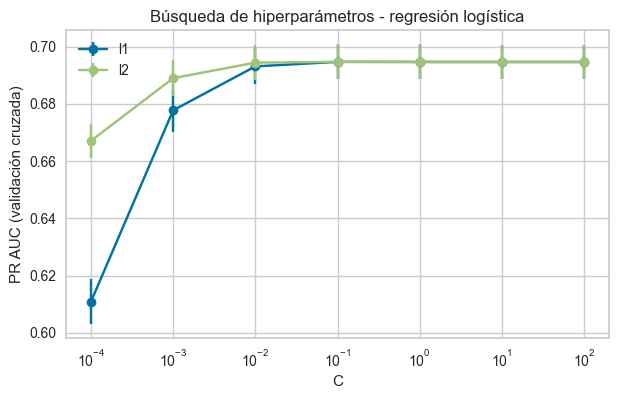

In [49]:
# PR AUC en validación cruzada según C
plt.figure(figsize=(7, 4))
for pen in ["l1", "l2"]:
    sub = res_cv[res_cv["penalty"] == pen]
    plt.errorbar(sub["C"].astype(float), sub["PR AUC (media)"], yerr=sub["PR AUC (desvío)"],
                 marker="o", capsize=3, label=pen)
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("PR AUC (validación cruzada)")
plt.title("Búsqueda de hiperparámetros - regresión logística")
plt.legend()
plt.show()

In [50]:
# se guarda el mejor modelo y se evalúa igual que en la sección 2: umbral que maximiza el F1 en validación
logreg_tuned = grid_search.best_estimator_
proba["LogReg tuned"] = {
    "train": logreg_tuned.predict_proba(X_train_s)[:, 1],
    "val": logreg_tuned.predict_proba(X_val_s)[:, 1],
    "test": logreg_tuned.predict_proba(X_test_s)[:, 1],
}
umbrales["LogReg tuned"] = mejores_umbrales(y_val, proba["LogReg tuned"]["val"])
UMBRAL_LR_TUNED = umbrales["LogReg tuned"][1]

# comparación en test: modelo de la sección 2 vs modelo optimizado
comp_tuned = pd.DataFrame({
    "LogReg (u=F1 máx)": metricas(y_test, proba["LogReg"]["test"], UMBRAL_LR),
    "LogReg tuned (u=F1 máx)": metricas(y_test, proba["LogReg tuned"]["test"], UMBRAL_LR_TUNED),
}).T
comp_tuned.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
LogReg (u=F1 máx),0.818,0.575,0.717,0.638,0.782,0.524,0.869,0.7
LogReg tuned (u=F1 máx),0.816,0.572,0.719,0.637,0.782,0.522,0.869,0.7


**Conclusiones de la búsqueda**

- Con `C` chico (0.0001 y 0.001) la regularización es demasiado fuerte y la PR AUC baja; con `l1` y `C = 0.0001` el modelo directamente no predice ninguna lluvia (F1 = 0). A partir de `C = 0.1` la PR AUC queda en un valor constante, cerca de 0.69.
- El mejor modelo (`C = 0.1`, `l2`) le gana al resto por una diferencia muchísimo menor al desvío entre folds, así que en la práctica da lo mismo cualquier `C` desde 0.1 hasta 100 y cualquiera de las dos penalizaciones.
- En test, el modelo optimizado y el de la sección 2 dan prácticamente las mismas métricas.
- Entonces la regresión logística no mejora ajustando hiperparámetros: lo que la limita es que es un modelo lineal, no la regularización.

## 5. Explicabilidad del modelo

Explicamos la regresión logística optimizada (`logreg_tuned`) con SHAP usando `LinearExplainer`.

- Los valores SHAP están en **log-odds**: un valor positivo empuja la predicción hacia "llueve" y uno negativo hacia "no llueve".
- El **valor base** es la predicción promedio del modelo sobre los datos de referencia. `shap` toma por defecto una muestra de 100 días de train, por eso el valor base (-2.04) no es exactamente el promedio de todo train. Para cada día, valor base + suma de sus valores SHAP = log-odds que predice el modelo.
- Se explican los datos de **test**. El umbral no modifica los valores SHAP: lo usamos para elegir qué días mirar según si el modelo acertó o no.

In [51]:
# explainer lineal con los datos de train como referencia y valores SHAP de test
feature_names = X_train_s.columns.tolist()
explainer = shap.LinearExplainer(logreg_tuned, X_train_s.values, feature_names=feature_names)
shap_values = explainer.shap_values(X_test_s.values)
valor_base = np.ravel(explainer.expected_value)[0]
print("Forma de los valores SHAP:", shap_values.shape, "| valor base:", round(float(valor_base), 3))

Forma de los valores SHAP: (28431, 25) | valor base: -2.036


### Explicabilidad local

Miramos dos días de test que llovieron: uno que el modelo detectó (verdadero positivo) y otro que no detectó (falso negativo), según el umbral de F1 máximo. Se eligen al azar con semilla fija.

In [52]:
# se eligen un verdadero positivo y un falso negativo de test con el umbral de F1 máximo
pred_test = (proba["LogReg tuned"]["test"] >= UMBRAL_LR_TUNED).astype(int)
y_test_arr = np.asarray(y_test)
rng = np.random.default_rng(SEED)
idx_vp = rng.choice(np.where((pred_test == 1) & (y_test_arr == 1))[0])  # predijo lluvia y llovió
idx_fn = rng.choice(np.where((pred_test == 0) & (y_test_arr == 1))[0])  # predijo que no llovía y llovió

for nombre, i in [("Verdadero positivo", idx_vp), ("Falso negativo", idx_fn)]:
    print(f"{nombre} (fila {i}): probabilidad de lluvia = {proba['LogReg tuned']['test'][i]:.3f}")

print(f"Umbral F1 Máximo logit: {np.log(UMBRAL_LR_TUNED / (1 - UMBRAL_LR_TUNED)):.3f}")

Verdadero positivo (fila 2451): probabilidad de lluvia = 0.726
Falso negativo (fila 21516): probabilidad de lluvia = 0.177
Umbral F1 Máximo logit: -0.954


Verdadero positivo


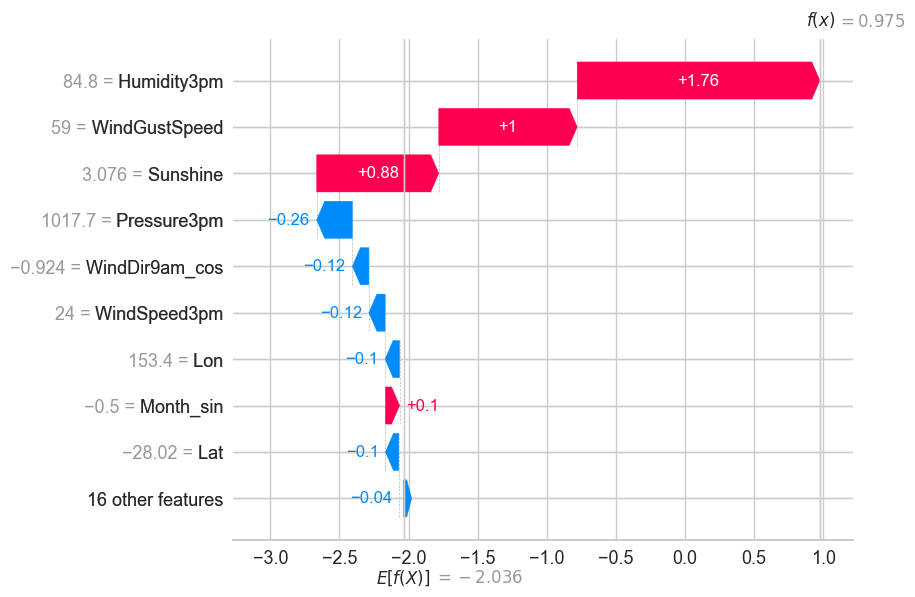

Falso negativo


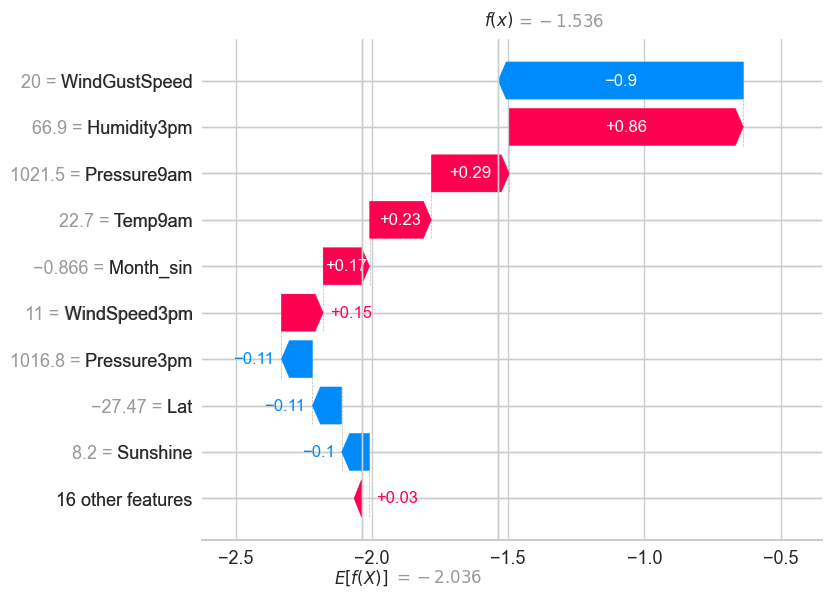

In [53]:
# gráfico local 1: waterfall de cada día
for nombre, i in [("Verdadero positivo", idx_vp), ("Falso negativo", idx_fn)]:
    explicacion = shap.Explanation(values=shap_values[i], base_values=valor_base,
                                   data=X_test_enc.iloc[i].values, feature_names=feature_names)
    print(nombre)
    shap.plots.waterfall(explicacion)

Verdadero positivo


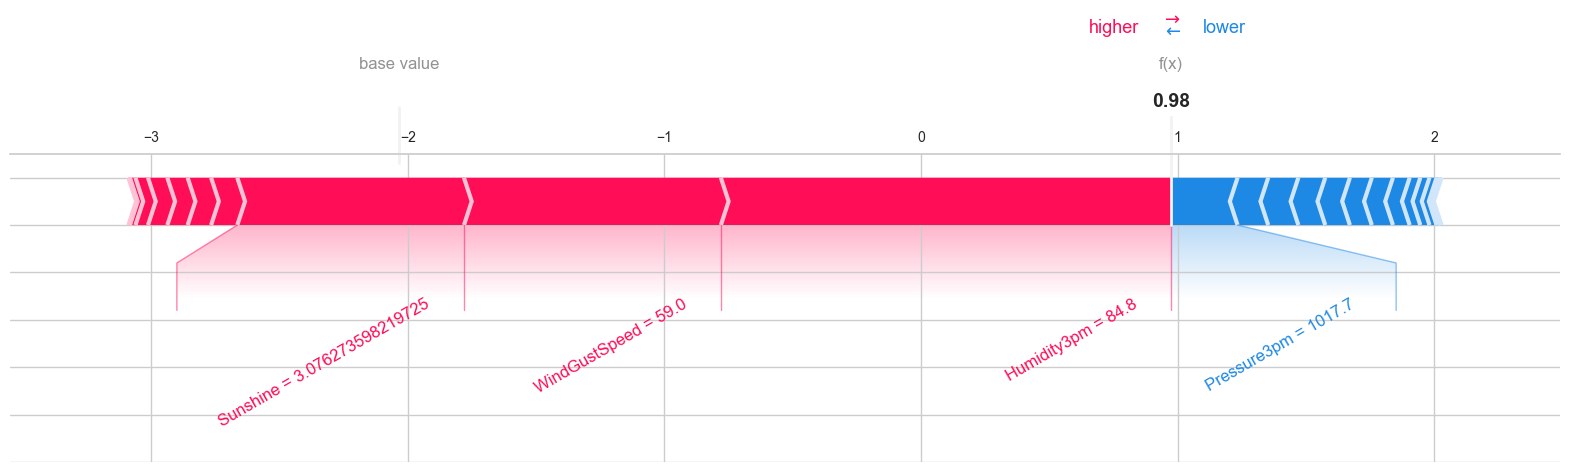

Falso negativo


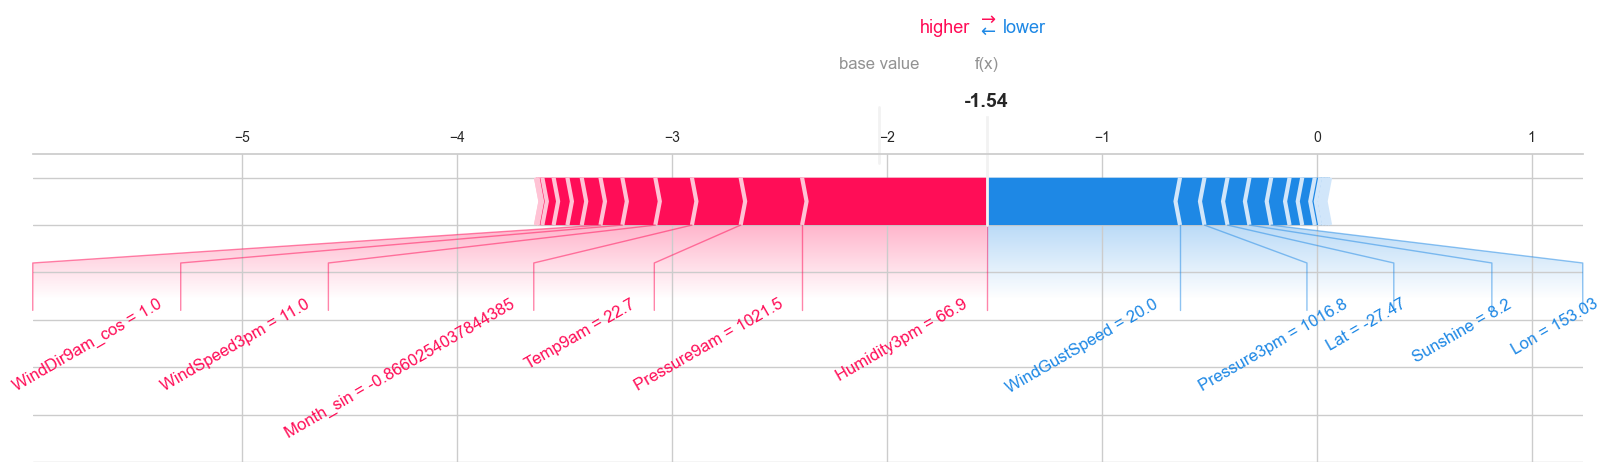

In [54]:
# gráfico local 2: force plot de cada día
for nombre, i in [("Verdadero positivo", idx_vp), ("Falso negativo", idx_fn)]:
    print(nombre)
    shap.force_plot(valor_base, shap_values[i], X_test_enc.iloc[i].values,
                    feature_names=feature_names, matplotlib=True, figsize=(20, 4), text_rotation=30)

**Qué se observa (local)**

- **Verdadero positivo.** El modelo da una probabilidad de lluvia de 0.73, muy por encima del umbral de -0.954, y efectivamente llovió. Desde el valor base (-2.04) la predicción sube hasta un log-odds de 0.98. Lo que más empuja hacia "llueve" es `Humidity3pm` = 84.8 (+1.76), después `WindGustSpeed` = 59 (+1.0) y `Sunshine` = 3.1 (+0.88): humedad alta, ráfagas fuertes y pocas horas de sol. Lo único importante en contra es `Pressure3pm` = 1017.7 (-0.26).
- **Falso negativo.** Llovió pero el modelo da una probabilidad de 0.18, menor al umbral, así que predice "no llueve". Su log-odds es -1.54 y el umbral es -0.954, o sea que le faltaron unos 0.586 para acertar. `Humidity3pm` = 66.9 empuja hacia la lluvia (+0.86), pero `WindGustSpeed` = 20 casi lo cancela (-0.9). El resto suma poco (`Pressure9am` +0.29, `Temp9am` +0.23, el mes +0.17) y `Pressure3pm`, `Lat` y `Sunshine` restan un poco. Ese día no tiene las señales que el modelo asocia con lluvia (ráfagas fuertes, humedad muy alta, poco sol). Como solo ve las condiciones de hoy y es lineal, este tipo de error es esperable.
- Los force plots muestran los mismos aportes que los waterfall, pero en una sola línea: lo rojo empuja hacia la derecha (más lluvia), lo azul hacia la izquierda, y f(x) es donde se cruzan.

### Explicabilidad global

Ahora se usan los valores SHAP de todo test. El gráfico de barras muestra la importancia de cada variable como el promedio del valor absoluto de su SHAP. El beeswarm muestra un punto por día: la posición horizontal es el valor SHAP (hacia dónde empuja) y el color es el valor de la variable (rojo alto, azul bajo).

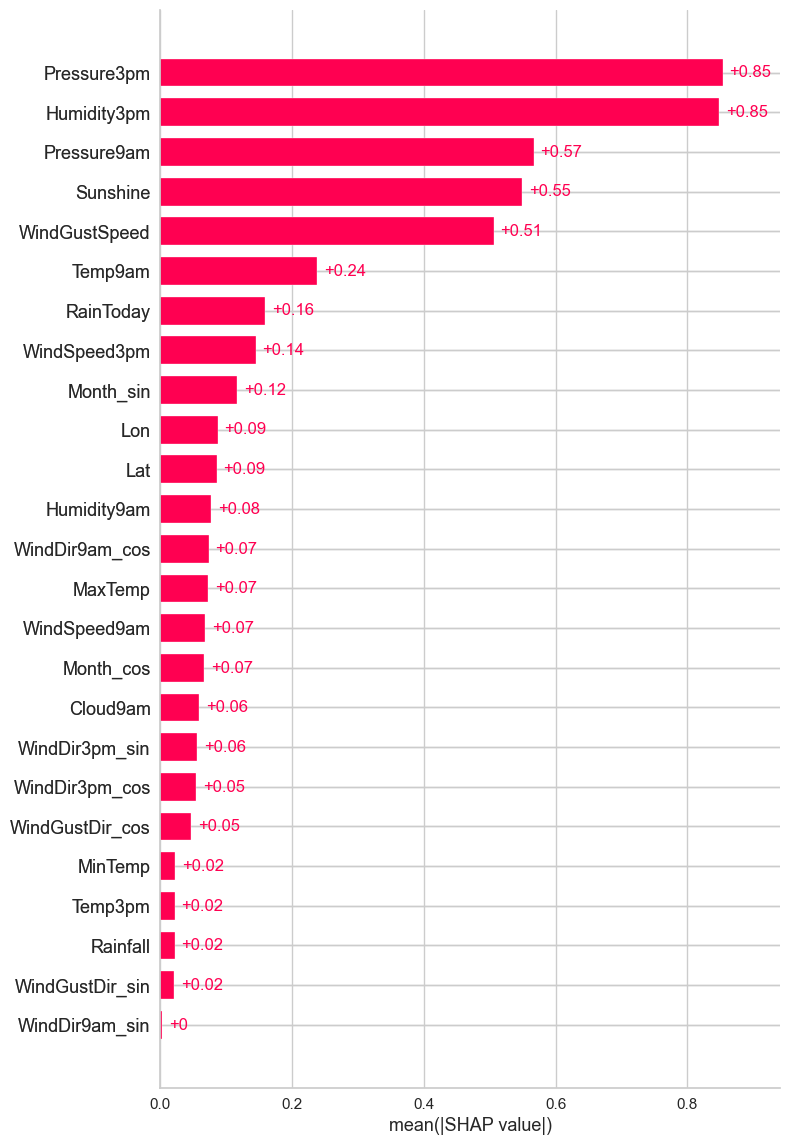

In [55]:
# valores SHAP de todo test, con los datos originales (sin escalar) para el color de los gráficos
explicacion_global = shap.Explanation(values=shap_values, base_values=np.full(len(shap_values), valor_base),
                                      data=X_test_enc, feature_names=feature_names)

# gráfico global 1: importancia media absoluta de cada variable
shap.plots.bar(explicacion_global, max_display=len(feature_names))

En el gráfico de barras cinco variables se despegan del resto: `Pressure3pm` (0.85), `Humidity3pm` (0.85), `Pressure9am` (0.57), `Sunshine` (0.55) y `WindGustSpeed` (0.51). Entre las cinco suman cerca del 70% del total de los SHAP medios absolutos. Después viene `Temp9am` (0.24) y todas las demás quedan por debajo de 0.2. Las barras solo muestran cuánto pesa cada variable, no hacia dónde empuja; eso lo vemos en el beeswarm.

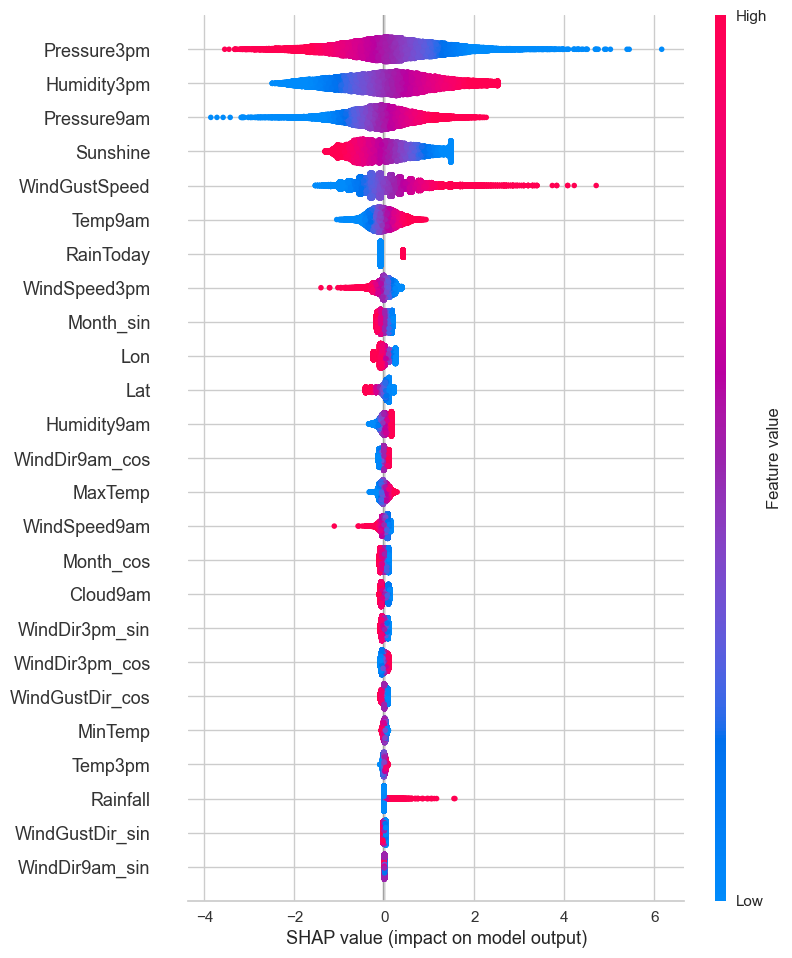

In [56]:
# gráfico global 2: beeswarm
shap.plots.beeswarm(explicacion_global, max_display=len(feature_names))

**Observaciones**

- `Humidity3pm`: los puntos rojos (humedad alta) están a la derecha y los azules a la izquierda. Más humedad a las 3 de la tarde aumenta la probabilidad de lluvia.
- `Pressure3pm`: es al revés, presión alta lleva a la izquierda y presión baja a la derecha. Las presiones muy bajas dan los aportes más grandes hacia la lluvia (hasta cerca de +6).
- `Pressure9am` tiene el signo contrario a `Pressure3pm`. Como las dos están muy correlacionadas no conviene leerlas por separado: el modelo usa sobre todo la diferencia entre ambas, y que la presión baje durante el día favorece la lluvia.
- `Sunshine`: pocas horas de sol empujan hacia la lluvia y muchas horas hacia la no lluvia. El borde derecho es recto porque no puede haber menos de 0 horas de sol.
- `WindGustSpeed`: las ráfagas fuertes empujan hacia la lluvia, con una cola larga a la derecha. Las ráfagas débiles restan, pero menos.
- `RainToday` forma dos grupos: haber llovido hoy suma unos ~0.4 y no haber llovido resta unos ~0.1.
- `Temp9am` suma a mayor temperatura, lo que parece raro. Pasa porque está muy correlacionada con `MaxTemp`, `MinTemp` y `Temp3pm`, y el modelo reparte entre ellas el efecto una vez que ya conoce la humedad y la presión. No hay que leerlo como una causa.
- `Lat` y `Lon` tienen aportes chicos: una vez que se conoce el estado del tiempo de ese día, la ubicación pesa poco.
- Como el modelo es lineal, para cada variable los colores quedan ordenados (todos los rojos de un lado y los azules del otro) y sin mezclarse: el efecto siempre va en el mismo sentido.

In [57]:
# ranking de importancia: SHAP medio absoluto de cada variable, su porcentaje sobre el total y el acumulado
importancia = pd.DataFrame({"SHAP medio absoluto": np.abs(shap_values).mean(axis=0)}, index=feature_names)
importancia = importancia.sort_values("SHAP medio absoluto", ascending=False)
importancia.round({"SHAP medio absoluto": 3, "% del total": 1, "% acumulado": 1})

,SHAP medio absoluto
Pressure3pm,0.854
Humidity3pm,0.848
Pressure9am,0.567
Sunshine,0.549
WindGustSpeed,0.506
Temp9am,0.238
RainToday,0.159
WindSpeed3pm,0.145
Month_sin,0.117
Lon,0.087


**Variables más y menos importantes**

- **Más importantes:** `Pressure3pm`, `Humidity3pm`, `Pressure9am`, `Sunshine` y `WindGustSpeed`. Tiene sentido: la lluvia aparece con presión baja, humedad alta, pocas horas de sol y ráfagas fuertes.
- **Menos importantes:** `WindDir9am_sin`, `WindGustDir_sin`, `Rainfall`, `Temp3pm` y `MinTemp`. Eso no quiere decir que no tengan relación con la lluvia: `Temp3pm` y `MinTemp` están muy correlacionadas con `MaxTemp` y `Temp9am`, que ya aportan esa información. Las direcciones de viento se dividen en seno y coseno, por lo que hay que mirar las dos columnas juntas.


## 6. AutoML con PyCaret

Usamos PyCaret para que entrene y compare automáticamente muchos modelos de clasificación. Como en clase, `setup` arma el entorno (con imputación iterativa) y `compare_models` entrena todos los modelos con validación cruzada y los ordena según una métrica.

**Decisiones:**
- **Datos:** le pasamos las mismas variables de la sección 1, pero sin imputar ni escalar porque eso lo hace PyCaret. `Sunshine` va con sus faltantes y los días sin viento ya marcados como `"Calma"`. Train se usa para entrenar y validación como conjunto de hold-out de PyCaret. Test no se toca hasta el final.
- **Preprocesamiento de PyCaret:** `imputation_type='iterative'`, como en clase. En lugar de los modelos LightGBM que usa PyCaret por defecto para imputar, usamos `BayesianRidge` para las numéricas (el mismo que usa el `IterativeImputer` de scikit-learn de la sección 1) y regresión logística para las categóricas (direcciones del viento). Además `normalize=True`, porque varios modelos (regresión logística, SVM, k-NN) necesitan las variables en la misma escala.
- **Validación cruzada:** 5 folds, igual que en el ítem 4.
- **Métrica para ordenar:** por defecto PyCaret ordena por accuracy, que no sirve con clases desbalanceadas. Ordenamos por `AUC` (ROC AUC), que no depende del umbral como la PR AUC del ítem 4 (PyCaret no la trae entre sus métricas). Nos quedamos con los 3 mejores.
- Después, como en el resto del trabajo, para cada modelo elegimos el umbral que maximiza el F1 en validación y evaluamos en test.

In [58]:
# PyCaret para clasificación (en clase se usó pycaret.regression)
from pycaret.classification import setup, compare_models, predict_model, pull

In [59]:
# datos para PyCaret: mismas variables sin imputar ni escalar, con los días sin viento marcados como "Calma"
def preparar_pycaret(X_, y_):
    X_ = X_.copy()
    for dir_col, vel_col in [("WindDir9am", "WindSpeed9am"), ("WindDir3pm", "WindSpeed3pm")]:
        X_.loc[X_[dir_col].isna() & (X_[vel_col] == 0), dir_col] = "Calma"
    X_["RainTomorrow"] = y_.values
    return X_

train_pc = preparar_pycaret(X_train, y_train)
val_pc = preparar_pycaret(X_val, y_val)
test_pc = preparar_pycaret(X_test, y_test)

In [61]:
# entorno de PyCaret: train para entrenar y validación como hold-out
# para imputar se usa BayesianRidge (numéricas) y regresión logística (categóricas) en lugar del LightGBM por defecto
entorno = setup(data=train_pc, test_data=val_pc, target="RainTomorrow", session_id=SEED,
                imputation_type="iterative", normalize=True, fold=5)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004079 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2626
[LightGBM] [Info] Number of data points in the train set: 85115, number of used features: 21
[LightGBM] [Info] Start training from score 23.196677
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.010746 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2625
[LightGBM] [Info] Number of data points in the train set: 84908, number of used features: 21
[LightGBM] [Info] Start training from score 12.157817
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003577 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2626
[LightGBM] [Info] Number of data points in the train set: 84762, number of used features: 21
[LightGBM] [Info] Start t

,Description,Value
0,Session id,42
1,Target,RainTomorrow
2,Target type,Binary
3,Original data shape,"(113722, 23)"
4,Transformed data shape,"(113722, 93)"
5,Transformed train set shape,"(85291, 93)"
6,Transformed test set shape,"(28431, 93)"
7,Numeric features,19
8,Categorical features,3
9,Rows with missing values,57.0%


In [77]:
# se entrenan y comparan los modelos con validación cruzada sobre train, ordenados por AUC; se guardan los 3 mejores
# La comparación completa tarda varios minutos (105 minutos), así que se guarda en caché para no repetirla cada vez que se ejecuta el notebook.
CACHE_AUTOML = Path("cache_pycaret_automl.joblib")

if CACHE_AUTOML.exists():
    # Si ya existe la caché, se recuperan los modelos entrenados y la tabla.
    cache_automl = joblib.load(CACHE_AUTOML)
    mejores = cache_automl["mejores"]
    tabla_automl = cache_automl["tabla_automl"]
    print("Se cargaron los resultados de AutoML desde la caché.")
    display(tabla_automl.round(3))
else:
    # Solo se ejecuta la comparación completa si todavía no existe una caché.
    mejores = compare_models(sort="AUC", n_select=3)
    tabla_automl = pull()
    joblib.dump(
        {"mejores": mejores, "tabla_automl": tabla_automl},
        CACHE_AUTOML
    )
    print("Se ejecutó AutoML y se guardaron los resultados para próximos usos.")

Se cargaron los resultados de AutoML desde la caché.


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lr,Logistic Regression,0.846,0.0,0.515,0.721,0.601,0.509,0.520,87.130
knn,K Neighbors Classifier,0.807,0.0,0.349,0.626,0.448,0.343,0.364,96.488
nb,Naive Bayes,0.414,0.0,0.949,0.273,0.423,0.114,0.207,78.928
dt,Decision Tree Classifier,0.788,0.0,0.538,0.526,0.532,0.395,0.395,83.276
svm,SVM - Linear Kernel,0.838,0.0,0.499,0.695,0.580,0.483,0.494,81.060
ridge,Ridge Classifier,0.844,0.0,0.474,0.739,0.577,0.487,0.505,79.472
rf,Random Forest Classifier,0.856,0.0,0.506,0.774,0.612,0.528,0.546,87.938
qda,Quadratic Discriminant Analysis,0.309,0.0,0.904,0.233,0.369,0.021,0.050,98.832
ada,Ada Boost Classifier,0.844,0.0,0.507,0.716,0.593,0.501,0.512,89.436
gbc,Gradient Boosting Classifier,0.853,0.0,0.518,0.749,0.613,0.526,0.539,86.464


In [ ]:
# probabilidad de lluvia de un modelo de PyCaret (predict_model devuelve la clase predicha y la probabilidad de esa clase)
def proba_pycaret(modelo, datos):
    pred = predict_model(modelo, data=datos.drop(columns="RainTomorrow"))
    p_predicha = pred["prediction_score"].to_numpy()
    return np.where(pred["prediction_label"].astype(int) == 1, p_predicha, 1 - p_predicha)

# para cada uno de los 3 mejores se elige el umbral de F1 máx en validación y se evalúa en test
nombres = tabla_automl["Model"].head(3).tolist()
proba_automl, umbral_automl, filas = {}, {}, {}
for nombre, modelo in zip(nombres, mejores):
    proba_automl[nombre] = {"val": proba_pycaret(modelo, val_pc), "test": proba_pycaret(modelo, test_pc)}
    umbral_automl[nombre] = mejores_umbrales(y_val, proba_automl[nombre]["val"])[1]
    filas[nombre + " (u=F1 máx)"] = metricas(y_test, proba_automl[nombre]["test"], umbral_automl[nombre])

# se agrega la regresión logística optimizada para comparar
res_automl = pd.concat([comp_tuned.loc[["LogReg tuned (u=F1 máx)"]], pd.DataFrame(filas).T])
res_automl.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
LogReg tuned (u=F1 máx),0.816327,0.571820,0.719485,0.637210,0.781899,0.522496,0.869377,0.699744
Logistic Regression (u=F1 máx),0.822166,0.585164,0.710386,0.641723,0.782427,0.529285,0.871411,0.701559
K Neighbors Classifier (u=F1 máx),0.777532,0.503257,0.593976,0.544866,0.712275,0.401381,0.772924,0.498153
Naive Bayes (u=F1 máx),0.713236,0.415503,0.686225,0.517603,0.703633,0.351747,0.741219,0.388900


### Observaciones

En la tabla de comparación, **LightGBM** obtuvo la mayor `accuracy` (0.8604) y el mayor `F1` (0.6389), seguido por **Gradient Boosting** (`F1 = 0.6127`) y **Random Forest** (`F1 = 0.6119`). **Naive Bayes** presentó un `recall` elevado (0.9489), pero una `precision` baja (0.2728), lo que indica que detecta gran parte de los días lluviosos a costa de generar numerosas falsas alarmas.

Sin embargo, la columna `AUC` de la salida de PyCaret figura como 0.0 para todos los modelos. Por este motivo, no es posible extraer conclusiones de esa métrica ni verificar que el ordenamiento solicitado por `AUC` se haya aplicado correctamente. Los tres modelos que finalmente se seleccionaron fueron **Regresión logística**, **K Neighbors** y **Naive Bayes**.

Al evaluarlos en el conjunto de test, ajustando el umbral para maximizar `F1` sobre validación, la **Regresión logística** de PyCaret obtuvo el mejor resultado: `F1 = 0.642`, `ROC AUC = 0.871` y `PR AUC = 0.702`. Estos valores son ligeramente superiores a los de la regresión logística optimizada en el punto 4 (`F1 = 0.637`, `ROC AUC = 0.869` y `PR AUC = 0.700`). En cambio, **KNN** y **Naive Bayes** tuvieron un rendimiento inferior.

**En conclusión**, AutoML permitió explorar varios algoritmos de forma automatizada, pero no necesariamente encontró un modelo claramente superior al que ya habíamos optimizado. En este caso, la **Regresión logística** siguió siendo una alternativa competitiva y más sencilla. También se observa que la elección del modelo depende de la métrica considerada: una `accuracy` elevada por sí sola no garantiza un buen equilibrio entre `precisión` y `recall` en un dataset desbalanceado.